In [1]:
import os
import sys
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from collections import defaultdict
import pickle

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

# LPIPS
import lpips

# Scikit-learn
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from scipy.stats import spearmanr, pearsonr

print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

import warnings
warnings.filterwarnings('ignore')


/home/youkyoung/.conda/envs/med/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.5.1+cu124
CUDA Available: True


In [2]:

CFG = {
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "seed": 42,
    
    # Paths
    "data_root": "../data/processed_with_skullstrip",
    "draft_dir": "./draft_results",
    "output_dir": "./quality_comparison",
    
    # Dataset
    "img_size": 256,
    "train_ratio": 0.9,
    "batch_size": 16,
    "num_workers": 4,
    
    # Option 1: Learned Predictor
    "predictor_epochs": 50,
    "predictor_lr": 1e-4,
    
    # Option 2: Distribution Matching
    "n_gmm_components": 10,
    "feature_model": "resnet50",  # resnet50, vgg16, densenet121
    
    # Visualization
    "top_k": 10,
    "tsne_samples": 3000,  # Limit for t-SNE visualization
}

torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])

Path(CFG["output_dir"]).mkdir(parents=True, exist_ok=True)

print("="*80)
print("Configuration")
print("="*80)
for k, v in CFG.items():
    print(f"  {k:25s}: {v}")
print("="*80)



Configuration
  device                   : cuda
  seed                     : 42
  data_root                : ../data/processed_with_skullstrip
  draft_dir                : ./draft_results
  output_dir               : ./quality_comparison
  img_size                 : 256
  train_ratio              : 0.9
  batch_size               : 16
  num_workers              : 4
  predictor_epochs         : 50
  predictor_lr             : 0.0001
  n_gmm_components         : 10
  feature_model            : resnet50
  top_k                    : 10
  tsne_samples             : 3000


In [3]:

def load_image(path, size=256):
    """Load and preprocess image to [0, 1]"""
    img = Image.open(path).convert('L')
    img = img.resize((size, size), Image.BICUBIC)
    return np.array(img, dtype=np.float32) / 255.0


class DraftGTDataset(Dataset):
    """Dataset for Draft-GT pairs"""
    
    def __init__(self, data_root, draft_dir, mode='train', train_ratio=0.9, img_size=256):
        self.data_root = Path(data_root)
        self.draft_dir = Path(draft_dir)
        self.mode = mode
        self.img_size = img_size
        
        self.samples = self._collect_samples(train_ratio)
        print(f"  {mode}: {len(self.samples)} samples")
    
    def _collect_samples(self, train_ratio):
        samples = []
        
        for group in ['bleed', 'non_bleed']:
            group_dir = self.data_root / group
            if not group_dir.exists():
                continue
            
            for patient_dir in sorted(group_dir.iterdir()):
                if not patient_dir.is_dir():
                    continue
                
                patient = patient_dir.name
                ct_dir = patient_dir / 'ct_axial'
                mri_dir = patient_dir / 'mri_b0_axial'
                
                if not (ct_dir.exists() and mri_dir.exists()):
                    continue
                
                # Match CT-MRI by filename
                ct_files = sorted(ct_dir.glob('*.png'))
                mri_files = sorted(mri_dir.glob('*.png'))
                
                ct_dict = {f.stem: f for f in ct_files}
                mri_dict = {f.stem: f for f in mri_files}
                common = sorted(set(ct_dict.keys()) & set(mri_dict.keys()))
                
                for slice_name in common:
                    draft_file = self.draft_dir / group / patient / f"{slice_name}.png"
                    if not draft_file.exists():
                        continue
                    
                    samples.append({
                        'group': group,
                        'patient': patient,
                        'slice_name': slice_name,
                        'draft_path': draft_file,
                        'gt_path': mri_dict[slice_name],
                        'ct_path': ct_dict[slice_name],
                    })
        
        # Train/val split by patient
        samples.sort(key=lambda x: x['patient'])
        patients = sorted(set(s['patient'] for s in samples))
        n_train = int(len(patients) * train_ratio)
        train_patients = set(patients[:n_train])
        
        if self.mode == 'train':
            return [s for s in samples if s['patient'] in train_patients]
        else:
            return [s for s in samples if s['patient'] not in train_patients]
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx]
        
        # Load draft and GT
        draft = load_image(sample['draft_path'], self.img_size)
        gt = load_image(sample['gt_path'], self.img_size)
        
        # To tensor [-1, 1]
        draft_t = torch.from_numpy(draft).unsqueeze(0).float() * 2 - 1
        gt_t = torch.from_numpy(gt).unsqueeze(0).float() * 2 - 1
        
        # Convert Path objects to strings
        meta = {
            'group': sample['group'],
            'patient': sample['patient'],
            'slice_name': sample['slice_name'],
            'draft_path': str(sample['draft_path']),  # Path → str
            'gt_path': str(sample['gt_path']),        # Path → str
            'ct_path': str(sample['ct_path']),        # Path → str
        }
        
        return {
            'draft': draft_t,
            'gt': gt_t,
            'sample_id': f"{sample['patient']}_{sample['slice_name']}",
            'meta': meta,
        }

In [4]:
print("\n" + "="*80)
print("Loading Dataset")
print("="*80)

train_dataset = DraftGTDataset(
    CFG["data_root"], 
    CFG["draft_dir"],
    mode='train',
    train_ratio=CFG["train_ratio"],
    img_size=CFG["img_size"]
)

val_dataset = DraftGTDataset(
    CFG["data_root"],
    CFG["draft_dir"],
    mode='val',
    train_ratio=CFG["train_ratio"],
    img_size=CFG["img_size"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CFG["batch_size"],
    shuffle=True,
    num_workers=CFG["num_workers"],
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=True
)

print(f"\n✓ Dataset loaded")
print(f"  Train: {len(train_dataset)} samples")
print(f"  Val:   {len(val_dataset)} samples")
print("="*80)


Loading Dataset
  train: 5289 samples
  val: 589 samples

✓ Dataset loaded
  Train: 5289 samples
  Val:   589 samples


## LPIPS 기반

In [5]:
print("\n" + "="*80)
print("Loading LPIPS Model (Teacher)")
print("="*80)

lpips_model = lpips.LPIPS(net='alex', verbose=False).to(CFG["device"])
lpips_model.eval()

# Freeze
for param in lpips_model.parameters():
    param.requires_grad = False

print("✓ LPIPS model loaded and frozen")
print("="*80)


Loading LPIPS Model (Teacher)
✓ LPIPS model loaded and frozen


In [6]:
class QualityPredictor(nn.Module):
    """
    Quality predictor trained with LPIPS as teacher
    Input: Draft image (no GT needed!)
    Output: Quality score [0, 1] (higher = better)
    """
    
    def __init__(self, backbone='resnet50'):
        super().__init__()
        
        if backbone == 'resnet50':
            resnet = models.resnet50(pretrained=True)
            self.features = nn.Sequential(*list(resnet.children())[:-2])
            feat_dim = 2048
        elif backbone == 'vgg16':
            vgg = models.vgg16(pretrained=True)
            self.features = nn.Sequential(*list(vgg.features.children())[:23])
            feat_dim = 512
        elif backbone == 'densenet121':
            densenet = models.densenet121(pretrained=True)
            self.features = densenet.features
            feat_dim = 1024
        else:
            raise ValueError(f"Unknown backbone: {backbone}")
        
        # Freeze early layers
        for name, param in self.features.named_parameters():
            if 'layer4' not in name and 'features.norm5' not in name:  # Only train last layers
                param.requires_grad = False
        
        # Quality prediction head
        self.quality_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(feat_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
            nn.Sigmoid()  # 0-1 quality score
        )
    
    def forward(self, x):
        # x: [B, 1, H, W] grayscale
        x = x.repeat(1, 3, 1, 1)  # → [B, 3, H, W]
        feat = self.features(x)
        quality = self.quality_head(feat)
        return quality.squeeze(-1)  # [B]


print("✓ QualityPredictor model defined")


✓ QualityPredictor model defined


In [7]:
def train_quality_predictor(model, train_loader, val_loader, lpips_model, cfg):
    """
    Train quality predictor with LPIPS as teacher
    """
    print("\n" + "="*80)
    print("Training Quality Predictor (Option 1)")
    print("="*80)
    
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg["predictor_lr"],
        weight_decay=1e-5
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, 
        T_max=cfg["predictor_epochs"]
    )
    
    best_val_corr = -1
    history = {'train_loss': [], 'val_loss': [], 'val_corr': []}
    
    for epoch in range(cfg["predictor_epochs"]):
        # Train
        model.train()
        train_losses = []
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{cfg['predictor_epochs']}")
        for batch in pbar:
            draft = batch['draft'].to(cfg["device"])
            gt = batch['gt'].to(cfg["device"])
            
            # Generate pseudo-label with LPIPS (teacher)
            with torch.no_grad():
                # LPIPS expects 3-channel input
                draft_3ch = draft.repeat(1, 3, 1, 1)
                gt_3ch = gt.repeat(1, 3, 1, 1)
                lpips_score = lpips_model(draft_3ch, gt_3ch).squeeze()  # [B]
                
                # Convert to quality (invert: lower LPIPS = higher quality)
                quality_target = 1 - lpips_score.clamp(0, 1)
            
            # Predict quality (student)
            quality_pred = model(draft)
            
            # Loss
            loss = F.mse_loss(quality_pred, quality_target)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            train_losses.append(loss.item())
            pbar.set_postfix({'loss': f"{loss.item():.4f}"})
        
        scheduler.step()
        
        # Validation
        model.eval()
        val_losses = []
        val_preds = []
        val_targets = []
        
        with torch.no_grad():
            for batch in val_loader:
                draft = batch['draft'].to(cfg["device"])
                gt = batch['gt'].to(cfg["device"])
                
                # LPIPS target
                draft_3ch = draft.repeat(1, 3, 1, 1)
                gt_3ch = gt.repeat(1, 3, 1, 1)
                lpips_score = lpips_model(draft_3ch, gt_3ch).squeeze()
                quality_target = 1 - lpips_score.clamp(0, 1)
                
                # Predict
                quality_pred = model(draft)
                
                loss = F.mse_loss(quality_pred, quality_target)
                
                val_losses.append(loss.item())
                val_preds.extend(quality_pred.cpu().numpy().tolist())
                val_targets.extend(quality_target.cpu().numpy().tolist())
        
        # Correlation
        val_corr = spearmanr(val_preds, val_targets)[0]
        
        # Log
        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_corr'].append(val_corr)
        
        print(f"Epoch {epoch+1}/{cfg['predictor_epochs']} - "
              f"Train Loss: {train_loss:.4f}, "
              f"Val Loss: {val_loss:.4f}, "
              f"Val Corr: {val_corr:.4f}")
        
        # Save best
        if val_corr > best_val_corr:
            best_val_corr = val_corr
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_corr': val_corr,
            }, Path(cfg["output_dir"]) / "best_quality_predictor.pt")
            print(f"  ✓ Best model saved (corr={val_corr:.4f})")
    
    print("\n✓ Training complete")
    print(f"  Best validation correlation: {best_val_corr:.4f}")
    print("="*80)
    
    return history

In [8]:
# Initialize and train
predictor = QualityPredictor(backbone=CFG["feature_model"]).to(CFG["device"])

print(f"\n✓ QualityPredictor initialized")
print(f"  Backbone: {CFG['feature_model']}")
print(f"  Trainable params: {sum(p.numel() for p in predictor.parameters() if p.requires_grad):,}")
print(f"  Total params: {sum(p.numel() for p in predictor.parameters()):,}")

# Train
history_predictor = train_quality_predictor(
    predictor,
    train_loader,
    val_loader,
    lpips_model,
    CFG
)


✓ QualityPredictor initialized
  Backbone: resnet50
  Trainable params: 1,180,673
  Total params: 24,688,705

Training Quality Predictor (Option 1)


Epoch 1/50: 100%|██████████| 331/331 [00:05<00:00, 59.67it/s, loss=0.0045]


Epoch 1/50 - Train Loss: 0.0131, Val Loss: 0.0027, Val Corr: 0.9639
  ✓ Best model saved (corr=0.9639)


Epoch 2/50: 100%|██████████| 331/331 [00:05<00:00, 63.22it/s, loss=0.0071]


Epoch 2/50 - Train Loss: 0.0055, Val Loss: 0.0031, Val Corr: 0.9733
  ✓ Best model saved (corr=0.9733)


...

Epoch 48/50 - Train Loss: 0.0015, Val Loss: 0.0010, Val Corr: 0.9859


Epoch 49/50: 100%|██████████| 331/331 [00:05<00:00, 62.29it/s, loss=0.0014]


Epoch 49/50 - Train Loss: 0.0016, Val Loss: 0.0011, Val Corr: 0.9854


Epoch 50/50: 100%|██████████| 331/331 [00:05<00:00, 63.12it/s, loss=0.0012]


Epoch 50/50 - Train Loss: 0.0014, Val Loss: 0.0011, Val Corr: 0.9857

✓ Training complete
  Best validation correlation: 0.9860


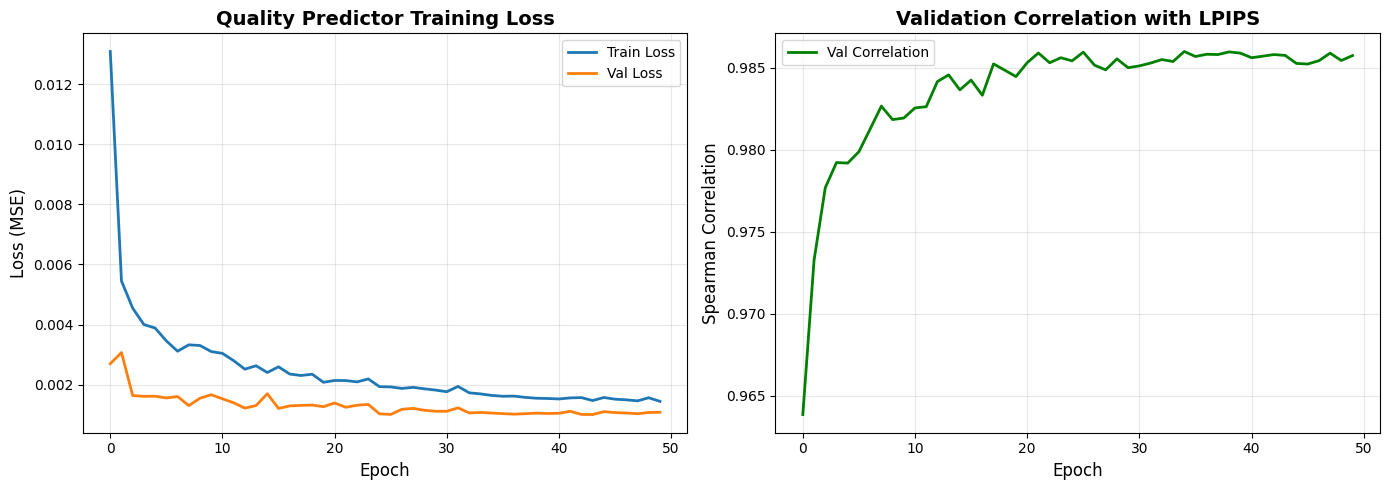

✓ Training history saved


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history_predictor['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(history_predictor['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss (MSE)', fontsize=12)
axes[0].set_title('Quality Predictor Training Loss', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Correlation
axes[1].plot(history_predictor['val_corr'], label='Val Correlation', linewidth=2, color='green')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Spearman Correlation', fontsize=12)
axes[1].set_title('Validation Correlation with LPIPS', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["output_dir"]) / "predictor_training_history.png", dpi=150, bbox_inches='tight')
plt.show()

print("✓ Training history saved")



In [27]:
# In[31]


if len(eval_dataset) > 0:
    print("\n" + "="*80)
    print("Computing Quality Scores on Eval Dataset")
    print("="*80)
    
    # Option 1: Learned Predictor
    eval_predictor_scores = []
    
    # Option 2: Distribution Matching
    eval_distribution_scores = []
    
    # Ground Truth: LPIPS
    eval_lpips_scores = []
    
    # Metadata - store as list of dicts, not batched
    eval_samples = []
    
    predictor.eval()
    feature_extractor.eval()
    lpips_model.eval()
    
    with torch.no_grad():
        for batch in tqdm(eval_loader, desc="Evaluating"):
            draft = batch['draft'].to(CFG["device"])
            gt = batch['gt'].to(CFG["device"])
            
            batch_size = draft.size(0)
            
            # Option 1
            pred_quality = predictor(draft)
            eval_predictor_scores.extend(pred_quality.cpu().numpy().tolist())
            
            # Option 2
            features = feature_extractor(draft)
            dist_quality = compute_distribution_quality(features.cpu().numpy(), gmm)
            eval_distribution_scores.extend(dist_quality.tolist())
            
            # LPIPS
            draft_3ch = draft.repeat(1, 3, 1, 1)
            gt_3ch = gt.repeat(1, 3, 1, 1)
            lpips_score = lpips_model(draft_3ch, gt_3ch).squeeze()
            lpips_quality = 1 - lpips_score.clamp(0, 1)
            eval_lpips_scores.extend(lpips_quality.cpu().numpy().tolist())
            
            # Store each sample's metadata individually
            for i in range(batch_size):
                eval_samples.append({
                    'patient': batch['meta']['patient'][i],
                    'slice_name': batch['meta']['slice_name'][i],
                    'draft_path': batch['meta']['draft_path'][i],
                    'gt_path': batch['meta']['gt_path'][i],
                    'ct_path': batch['meta']['ct_path'][i],
                })
    
    eval_predictor_scores = np.array(eval_predictor_scores)
    eval_distribution_scores = np.array(eval_distribution_scores)
    eval_lpips_scores = np.array(eval_lpips_scores)
    
    print(f"\n✓ Eval predictions complete")
    print(f"\nOption 1 (Predictor):")
    print(f"  Mean: {eval_predictor_scores.mean():.4f}")
    print(f"  Std:  {eval_predictor_scores.std():.4f}")
    print(f"  Min:  {eval_predictor_scores.min():.4f}")
    print(f"  Max:  {eval_predictor_scores.max():.4f}")
    
    print(f"\nOption 2 (Distribution):")
    print(f"  Mean: {eval_distribution_scores.mean():.4f}")
    print(f"  Std:  {eval_distribution_scores.std():.4f}")
    print(f"  Min:  {eval_distribution_scores.min():.4f}")
    print(f"  Max:  {eval_distribution_scores.max():.4f}")
    
    print(f"\nLPIPS (GT):")
    print(f"  Mean: {eval_lpips_scores.mean():.4f}")
    print(f"  Std:  {eval_lpips_scores.std():.4f}")
    print(f"  Min:  {eval_lpips_scores.min():.4f}")
    print(f"  Max:  {eval_lpips_scores.max():.4f}")
    
    print("="*80)


# In[32]


if len(eval_dataset) > 0:
    # Select top K and bottom K for each method
    k = 5  # Top/Bottom 5
    
    # Option 1
    opt1_sorted_indices = np.argsort(eval_predictor_scores)
    opt1_top_k = opt1_sorted_indices[-k:][::-1]
    opt1_bottom_k = opt1_sorted_indices[:k]
    
    # Option 2
    opt2_sorted_indices = np.argsort(eval_distribution_scores)
    opt2_top_k = opt2_sorted_indices[-k:][::-1]
    opt2_bottom_k = opt2_sorted_indices[:k]
    
    # LPIPS
    lpips_sorted_indices = np.argsort(eval_lpips_scores)
    lpips_top_k = lpips_sorted_indices[-k:][::-1]
    lpips_bottom_k = lpips_sorted_indices[:k]
    
    print("\n" + "="*80)
    print(f"Option 1: Top {k} (Best Quality)")
    print("="*80)
    for i, idx in enumerate(opt1_top_k, 1):
        sample = eval_samples[idx]  # ✅ Changed from eval_metas
        print(f"  {i}. {sample['patient']:15s} / {sample['slice_name']:20s}")
        print(f"     Opt1: {eval_predictor_scores[idx]:.4f}, "
              f"Opt2: {eval_distribution_scores[idx]:.4f}, "
              f"LPIPS: {eval_lpips_scores[idx]:.4f}")
    
    print(f"\n{'='*80}")
    print(f"Option 1: Bottom {k} (Worst Quality)")
    print("="*80)
    for i, idx in enumerate(opt1_bottom_k, 1):
        sample = eval_samples[idx]  # ✅ Changed from eval_metas
        print(f"  {i}. {sample['patient']:15s} / {sample['slice_name']:20s}")
        print(f"     Opt1: {eval_predictor_scores[idx]:.4f}, "
              f"Opt2: {eval_distribution_scores[idx]:.4f}, "
              f"LPIPS: {eval_lpips_scores[idx]:.4f}")


Computing Quality Scores on Eval Dataset


Evaluating: 100%|██████████| 4/4 [00:00<00:00,  5.16it/s]



✓ Eval predictions complete

Option 1 (Predictor):
  Mean: 0.5810
  Std:  0.2762
  Min:  0.0965
  Max:  0.9235

Option 2 (Distribution):
  Mean: 0.0000
  Std:  0.0000
  Min:  0.0000
  Max:  0.0000

LPIPS (GT):
  Mean: 0.5870
  Std:  0.2873
  Min:  0.1169
  Max:  0.9385

Option 1: Top 5 (Best Quality)
  1. CNUH_001        / 0024                
     Opt1: 0.9235, Opt2: 0.0000, LPIPS: 0.9255
  2. CNUH_X_001      / 0021                
     Opt1: 0.9152, Opt2: 0.0000, LPIPS: 0.9385
  3. CNUH_X_001      / 0019                
     Opt1: 0.9063, Opt2: 0.0000, LPIPS: 0.9104
  4. CNUH_002        / 0011                
     Opt1: 0.8868, Opt2: 0.0000, LPIPS: 0.8654
  5. CNUH_X_003      / 0021                
     Opt1: 0.8854, Opt2: 0.0000, LPIPS: 0.8914

Option 1: Bottom 5 (Worst Quality)
  1. CNUH_001        / 0020                
     Opt1: 0.0965, Opt2: 0.0000, LPIPS: 0.1169
  2. CNUH_002        / 0025                
     Opt1: 0.1248, Opt2: 0.0000, LPIPS: 0.1320
  3. CNUH_X_003      / 0

### 시각화 결과
- option 1: LPIPS (Teacher-Student 구조)
  -> 이게 option 2보다 좋음
- option 2: Distribution Matching (분포 기반)

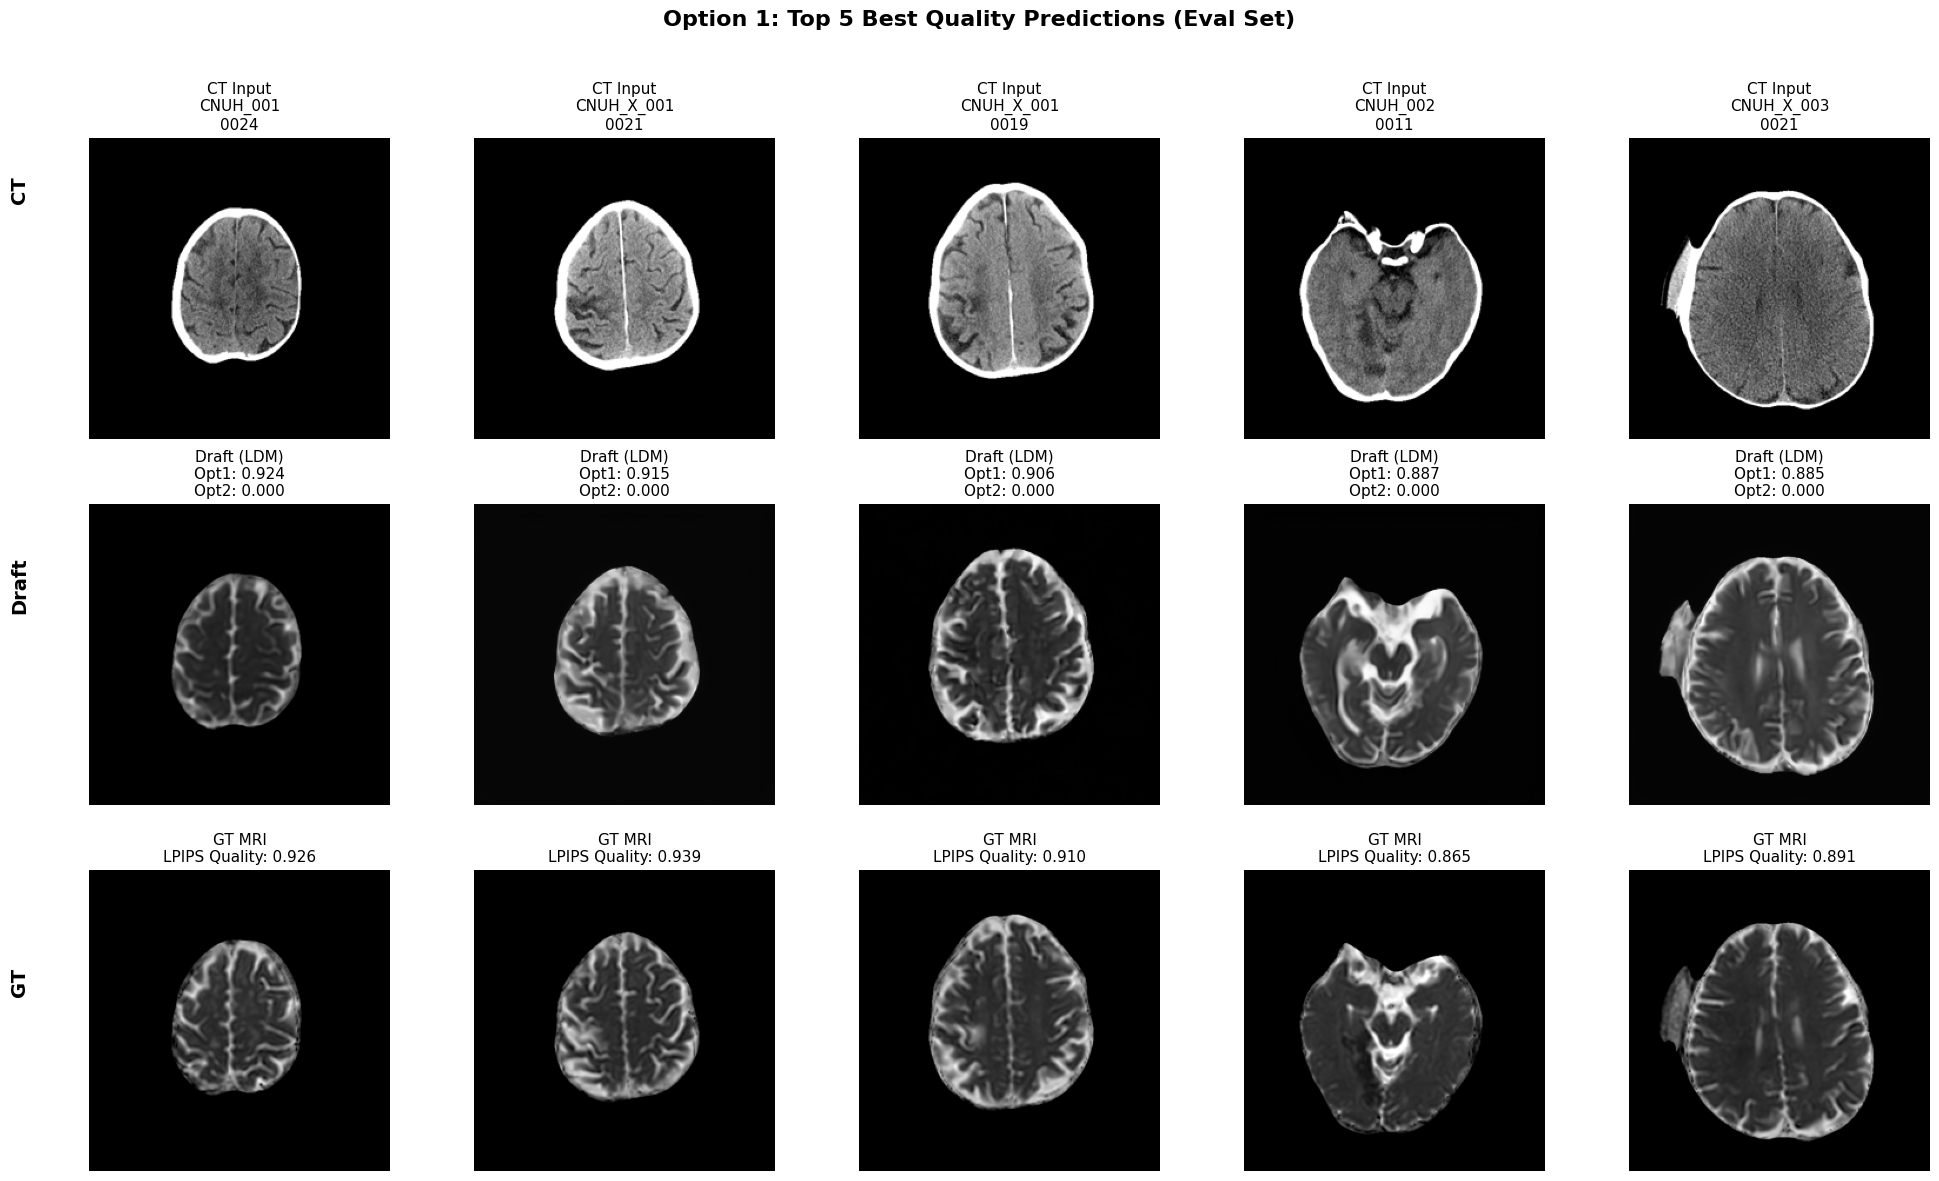

✓ Saved: quality_comparison/eval_option1_top5.png


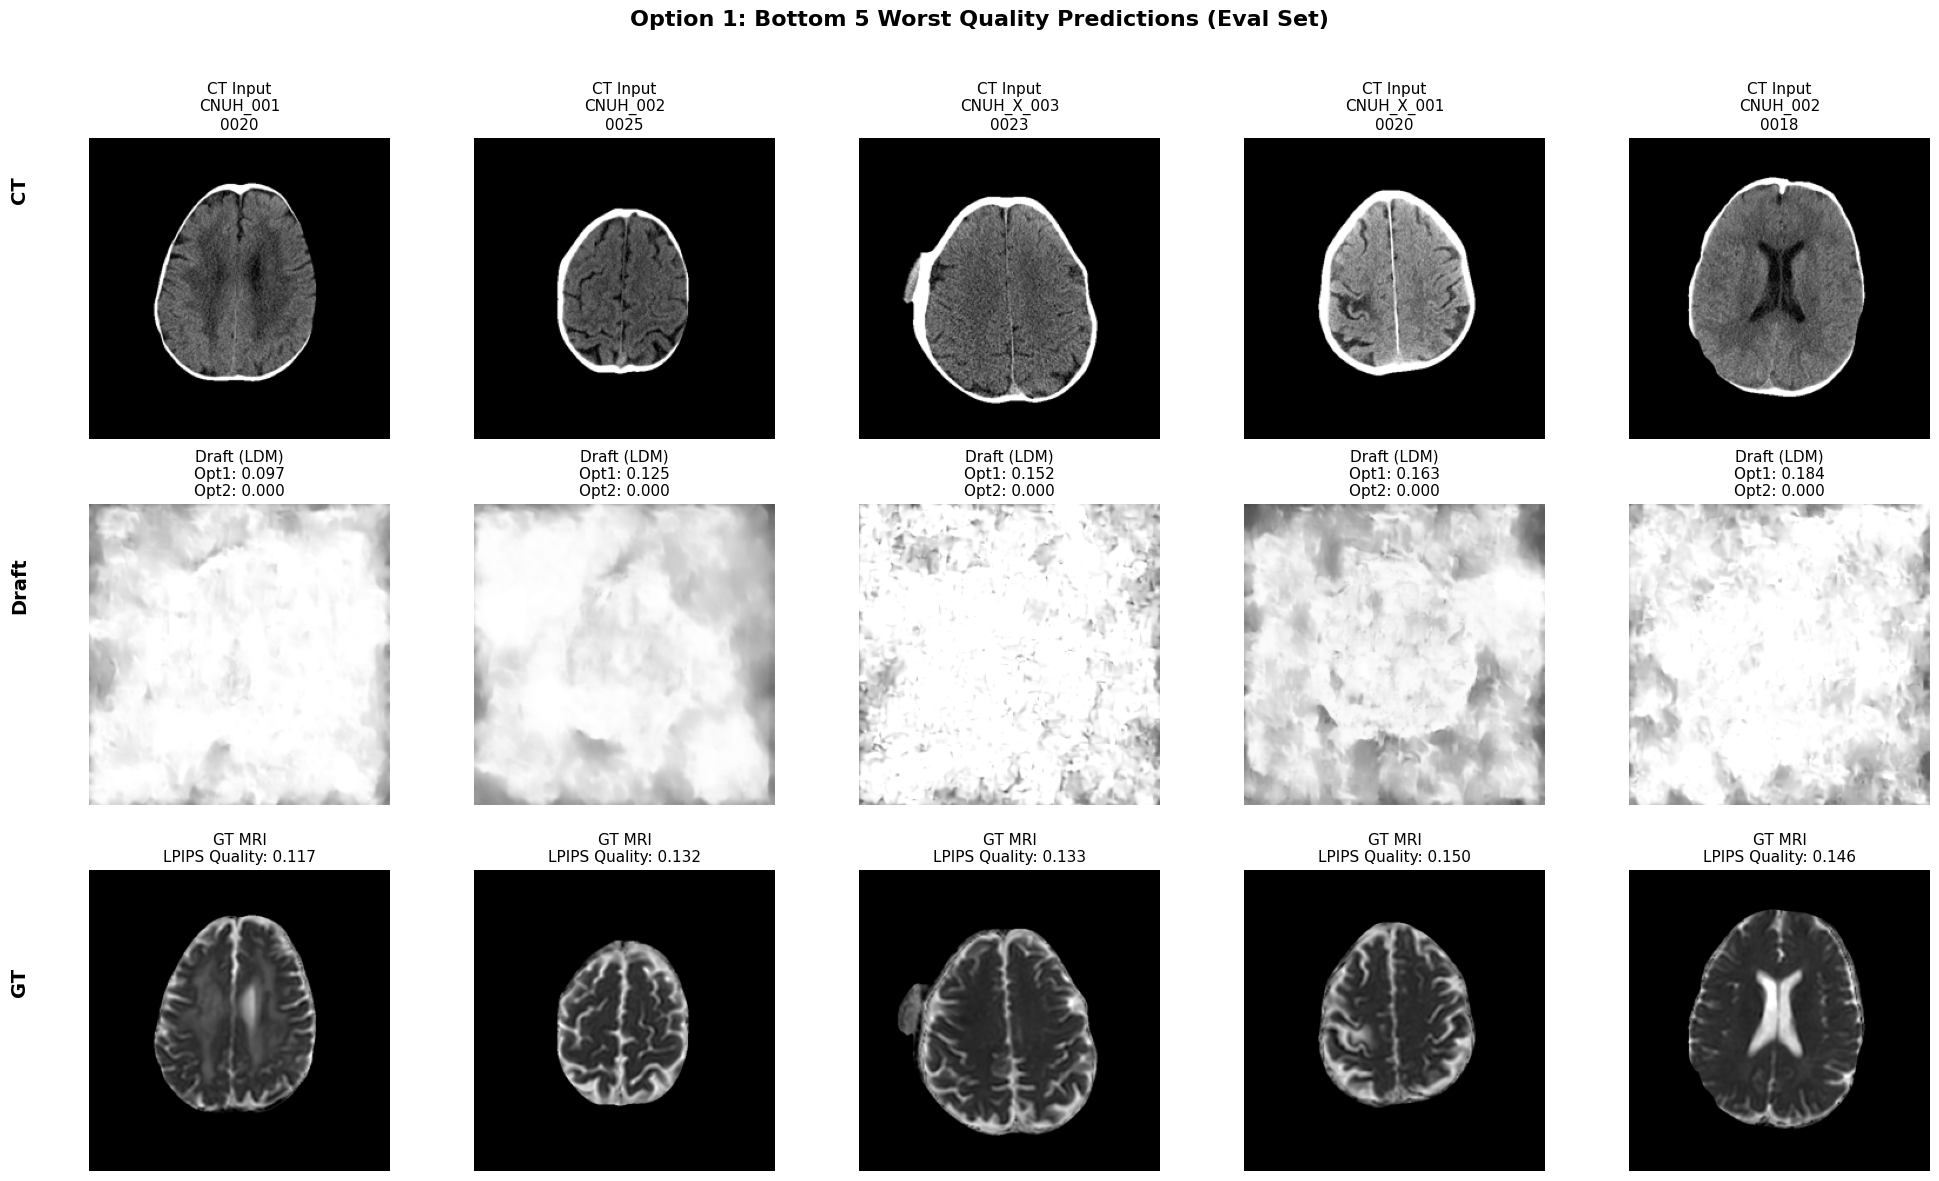

✓ Saved: quality_comparison/eval_option1_bottom5.png


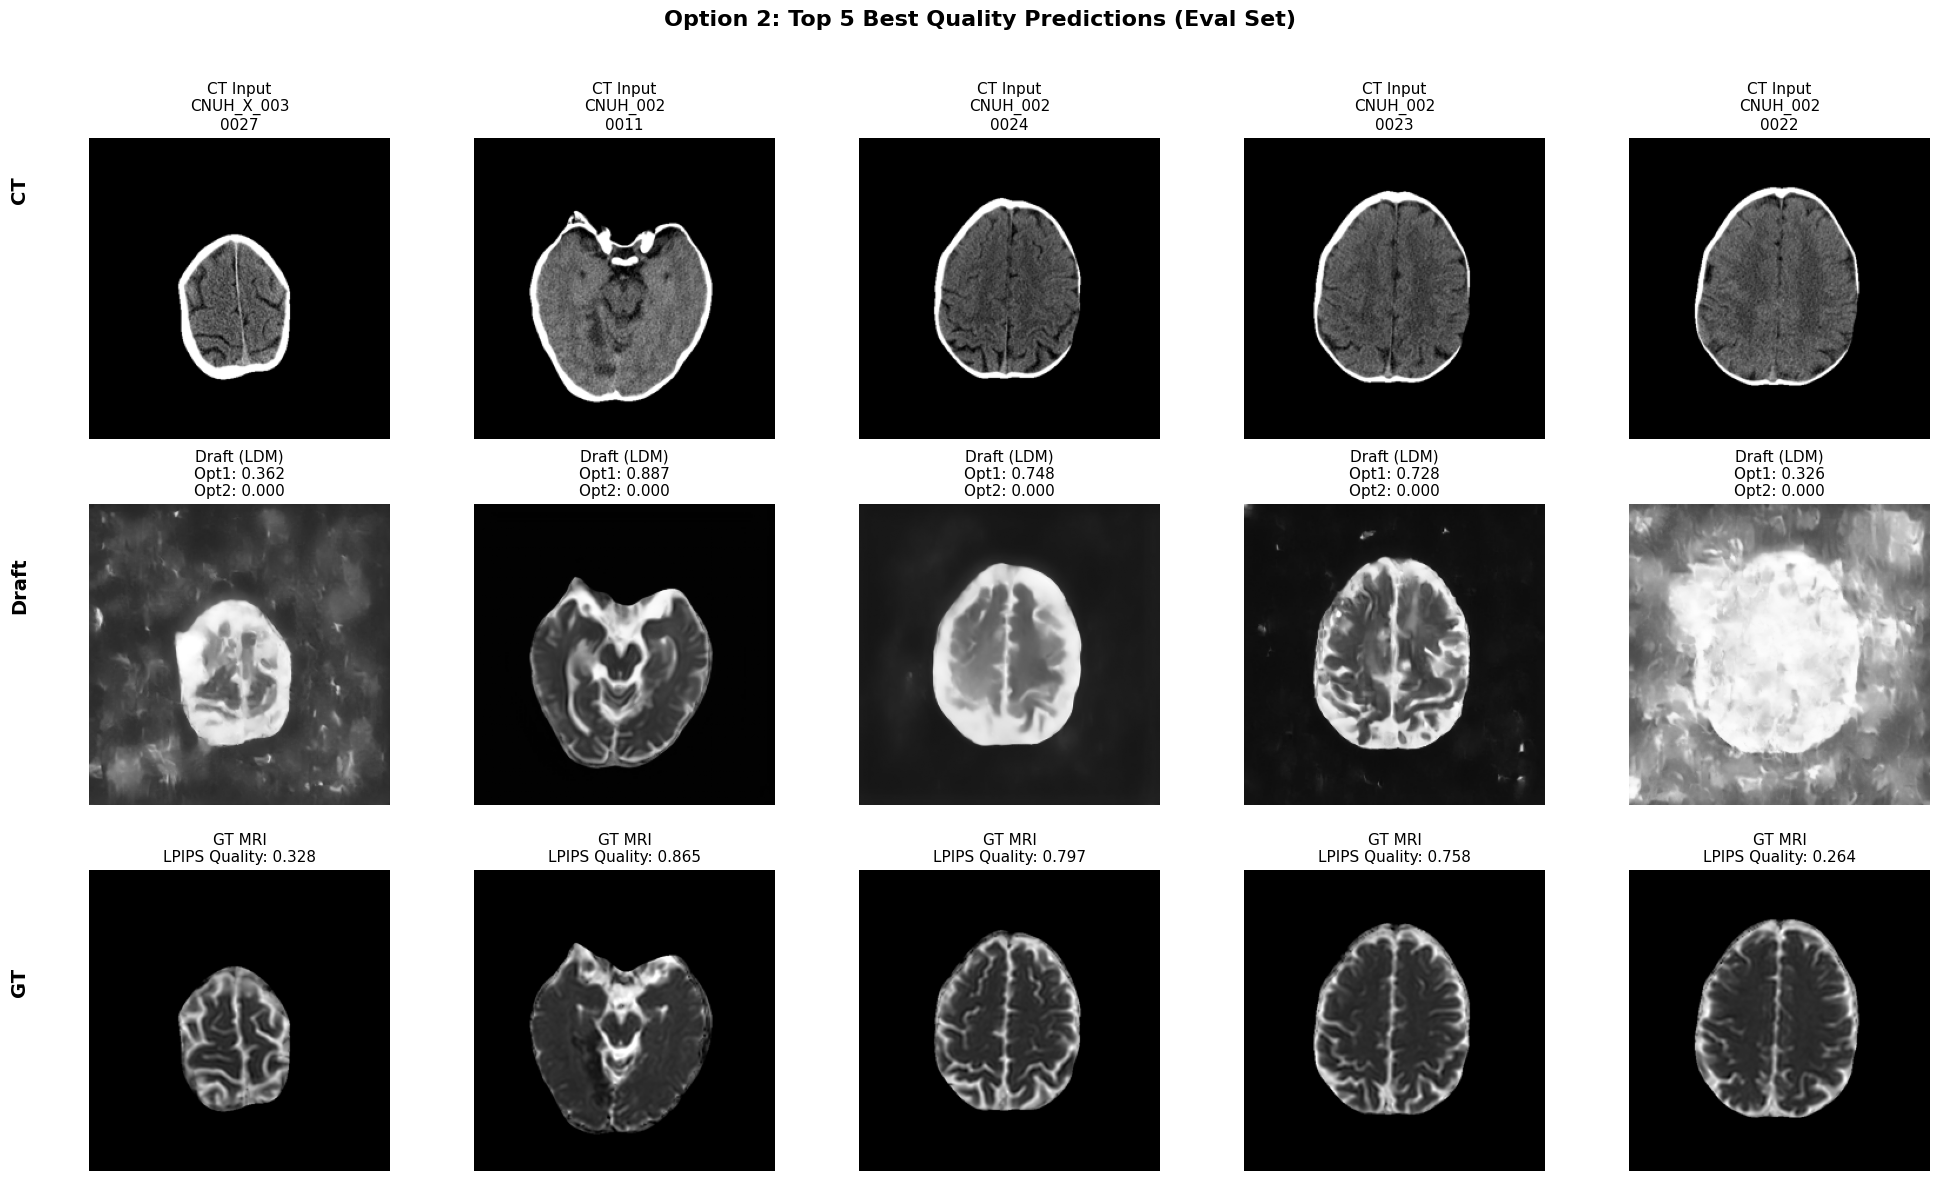

✓ Saved: quality_comparison/eval_option2_top5.png


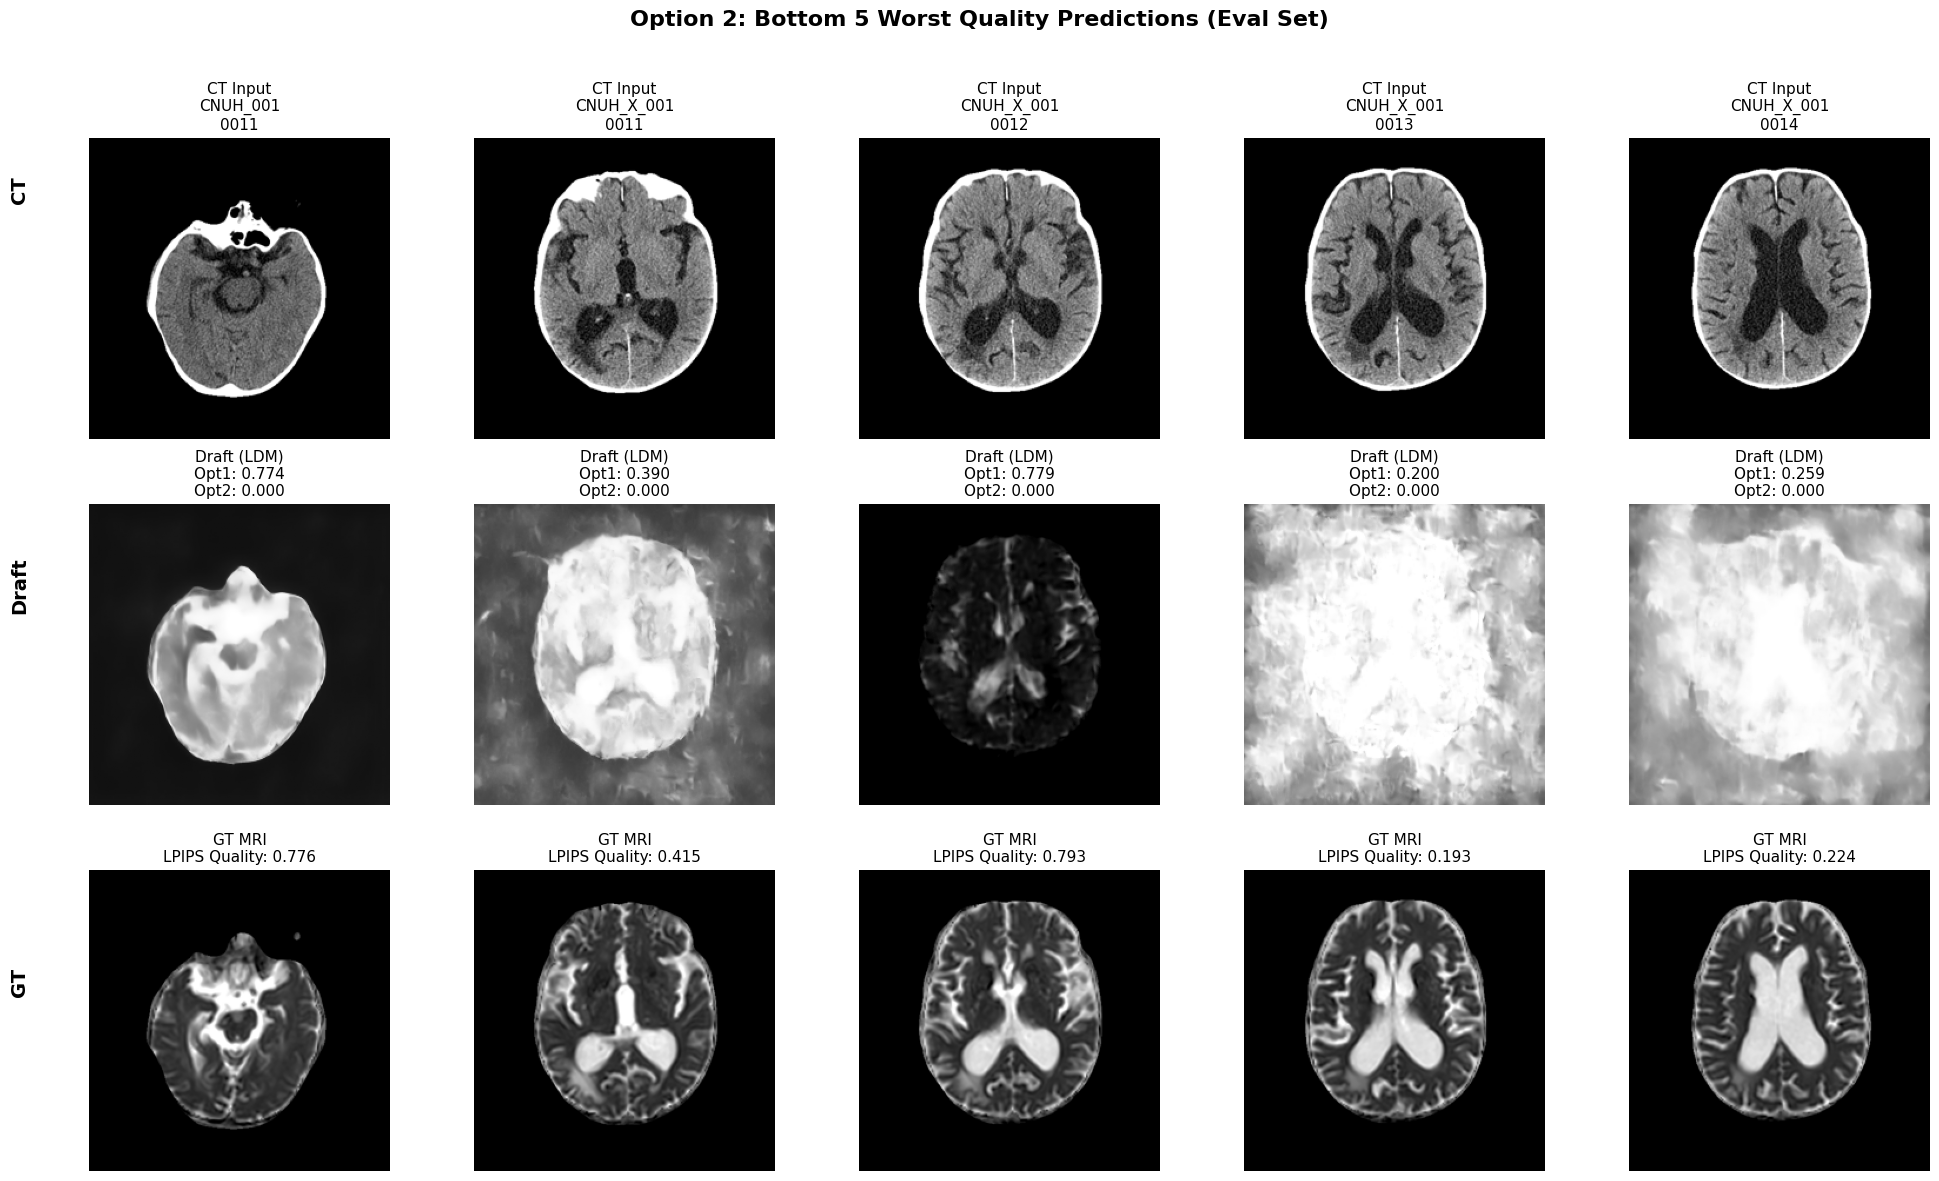

✓ Saved: quality_comparison/eval_option2_bottom5.png

✓ All eval visualizations saved


In [28]:

if len(eval_dataset) > 0:
    def visualize_eval_samples(indices, scores_opt1, scores_opt2, scores_lpips, 
                               metas, title, save_path):
        """
        Visualize eval samples with all three scores
        CT → Draft → GT with quality scores
        """
        n_samples = len(indices)
        fig, axes = plt.subplots(3, n_samples, figsize=(4*n_samples, 12))
        
        if n_samples == 1:
            axes = axes.reshape(3, 1)
        
        for i, idx in enumerate(indices):
            meta = metas[idx]
            
            # Load images
            ct = load_image(meta['ct_path'])
            draft = load_image(meta['draft_path'])
            gt = load_image(meta['gt_path'])
            
            # CT
            axes[0, i].imshow(ct, cmap='gray', vmin=0, vmax=1)
            axes[0, i].set_title(
                f"CT Input\n{meta['patient']}\n{meta['slice_name']}",
                fontsize=11
            )
            axes[0, i].axis('off')
            
            # Draft
            axes[1, i].imshow(draft, cmap='gray', vmin=0, vmax=1)
            axes[1, i].set_title(
                f"Draft (LDM)\n"
                f"Opt1: {scores_opt1[idx]:.3f}\n"
                f"Opt2: {scores_opt2[idx]:.3f}",
                fontsize=11
            )
            axes[1, i].axis('off')
            
            # GT
            axes[2, i].imshow(gt, cmap='gray', vmin=0, vmax=1)
            axes[2, i].set_title(
                f"GT MRI\n"
                f"LPIPS Quality: {scores_lpips[idx]:.3f}",
                fontsize=11
            )
            axes[2, i].axis('off')
        
        # Row labels
        fig.text(0.02, 0.83, 'CT', fontsize=14, fontweight='bold',
                ha='center', va='center', rotation=90)
        fig.text(0.02, 0.50, 'Draft', fontsize=14, fontweight='bold',
                ha='center', va='center', rotation=90)
        fig.text(0.02, 0.17, 'GT', fontsize=14, fontweight='bold',
                ha='center', va='center', rotation=90)
        
        plt.suptitle(title, fontsize=16, fontweight='bold', y=0.98)
        plt.tight_layout(rect=[0.03, 0, 1, 0.96])
        
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        plt.show()
        
        print(f"✓ Saved: {save_path}")
    
    
    # Visualize Option 1 top K
    visualize_eval_samples(
        opt1_top_k,
        eval_predictor_scores,
        eval_distribution_scores,
        eval_lpips_scores,
        eval_samples,
        f"Option 1: Top {k} Best Quality Predictions (Eval Set)",
        Path(CFG["output_dir"]) / "eval_option1_top5.png"
    )
    
    # Visualize Option 1 bottom K
    visualize_eval_samples(
        opt1_bottom_k,
        eval_predictor_scores,
        eval_distribution_scores,
        eval_lpips_scores,
        eval_samples,
        f"Option 1: Bottom {k} Worst Quality Predictions (Eval Set)",
        Path(CFG["output_dir"]) / "eval_option1_bottom5.png"
    )
    
    # Visualize Option 2 top K
    visualize_eval_samples(
        opt2_top_k,
        eval_predictor_scores,
        eval_distribution_scores,
        eval_lpips_scores,
        eval_samples,
        f"Option 2: Top {k} Best Quality Predictions (Eval Set)",
        Path(CFG["output_dir"]) / "eval_option2_top5.png"
    )
    
    # Visualize Option 2 bottom K
    visualize_eval_samples(
        opt2_bottom_k,
        eval_predictor_scores,
        eval_distribution_scores,
        eval_lpips_scores,
        eval_samples,
        f"Option 2: Bottom {k} Worst Quality Predictions (Eval Set)",
        Path(CFG["output_dir"]) / "eval_option2_bottom5.png"
    )
    
    print("\n✓ All eval visualizations saved")

In [29]:

print("\n" + "="*80)
print("Train Set LPIPS Distribution Analysis")
print("="*80)

# Compute LPIPS for entire train set
train_lpips_scores = []
train_predictor_scores = []
train_sample_info = []

predictor.eval()
lpips_model.eval()

with torch.no_grad():
    for batch in tqdm(train_loader, desc="Computing train set LPIPS"):
        draft = batch['draft'].to(CFG["device"])
        gt = batch['gt'].to(CFG["device"])
        
        # LPIPS
        draft_3ch = draft.repeat(1, 3, 1, 1)
        gt_3ch = gt.repeat(1, 3, 1, 1)
        lpips_score = lpips_model(draft_3ch, gt_3ch).squeeze()
        lpips_quality = 1 - lpips_score.clamp(0, 1)
        
        # Predictor
        pred_quality = predictor(draft)
        
        train_lpips_scores.extend(lpips_quality.cpu().numpy().tolist())
        train_predictor_scores.extend(pred_quality.cpu().numpy().tolist())
        
        # Store sample info
        batch_size = draft.size(0)
        for i in range(batch_size):
            train_sample_info.append({
                'patient': batch['meta']['patient'][i],
                'slice_name': batch['meta']['slice_name'][i],
            })

train_lpips_scores = np.array(train_lpips_scores)
train_predictor_scores = np.array(train_predictor_scores)

print(f"\n✓ Train set analysis complete")
print(f"  Total samples: {len(train_lpips_scores)}")
print("="*80)


Train Set LPIPS Distribution Analysis


Computing train set LPIPS: 100%|██████████| 331/331 [00:05<00:00, 62.99it/s]


✓ Train set analysis complete
  Total samples: 5289


In [30]:

# Statistics
print("\n" + "="*80)
print("LPIPS Quality Statistics (Train Set)")
print("="*80)

print(f"\nLPIPS Quality (1 - LPIPS):")
print(f"  Mean:       {train_lpips_scores.mean():.4f}")
print(f"  Std:        {train_lpips_scores.std():.4f}")
print(f"  Min:        {train_lpips_scores.min():.4f}")
print(f"  Max:        {train_lpips_scores.max():.4f}")
print(f"  Median:     {np.median(train_lpips_scores):.4f}")

print(f"\nPercentiles:")
for p in [10, 25, 50, 75, 90, 95, 99]:
    print(f"  {p:2d}th percentile: {np.percentile(train_lpips_scores, p):.4f}")

print(f"\nPredictor Quality:")
print(f"  Mean:       {train_predictor_scores.mean():.4f}")
print(f"  Std:        {train_predictor_scores.std():.4f}")
print(f"  Min:        {train_predictor_scores.min():.4f}")
print(f"  Max:        {train_predictor_scores.max():.4f}")
print(f"  Median:     {np.median(train_predictor_scores):.4f}")

print("="*80)


LPIPS Quality Statistics (Train Set)

LPIPS Quality (1 - LPIPS):
  Mean:       0.5743
  Std:        0.2788
  Min:        0.0285
  Max:        0.9691
  Median:     0.6059

Percentiles:
  10th percentile: 0.1922
  25th percentile: 0.3061
  50th percentile: 0.6059
  75th percentile: 0.8547
  90th percentile: 0.9022
  95th percentile: 0.9184
  99th percentile: 0.9422

Predictor Quality:
  Mean:       0.5708
  Std:        0.2710
  Min:        0.0638
  Max:        0.9492
  Median:     0.5829


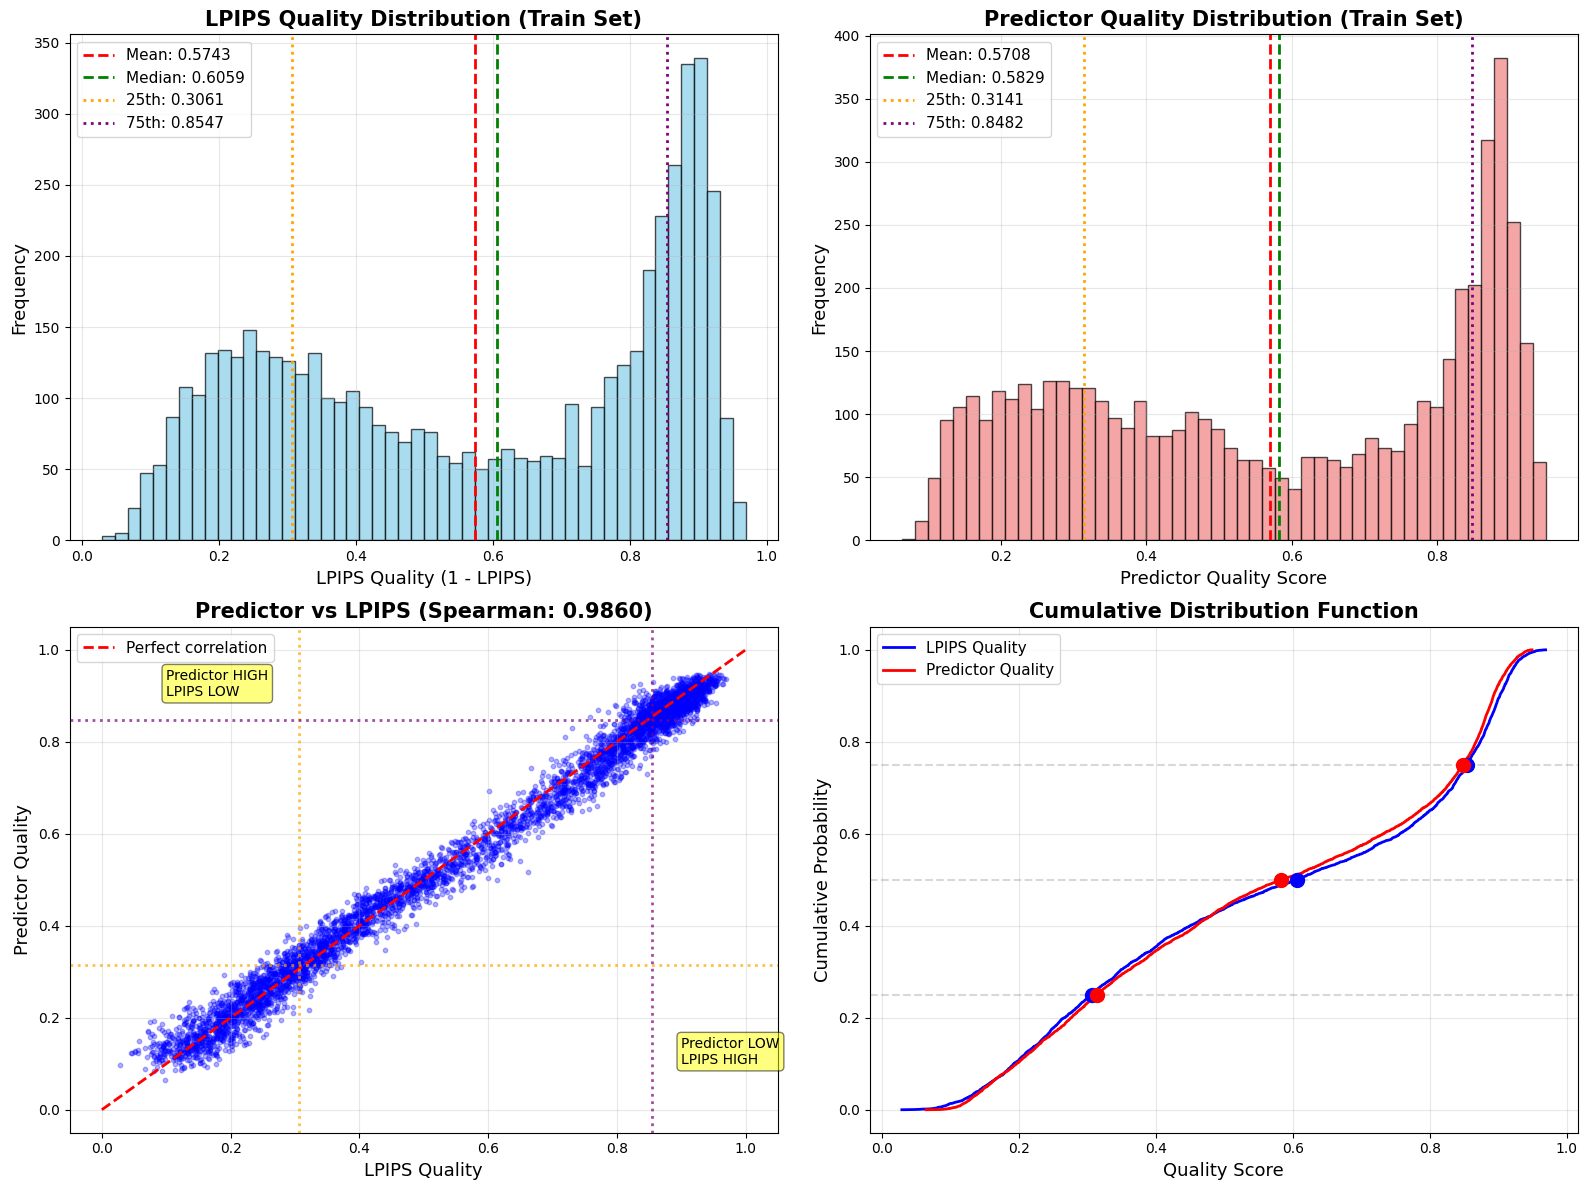

✓ Distribution visualization saved


In [31]:
# Histogram visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. LPIPS Quality Distribution
axes[0, 0].hist(train_lpips_scores, bins=50, edgecolor='black', alpha=0.7, color='skyblue')
axes[0, 0].axvline(train_lpips_scores.mean(), color='red', linestyle='--', 
                   linewidth=2, label=f'Mean: {train_lpips_scores.mean():.4f}')
axes[0, 0].axvline(np.median(train_lpips_scores), color='green', linestyle='--',
                   linewidth=2, label=f'Median: {np.median(train_lpips_scores):.4f}')

# Percentile lines
p25 = np.percentile(train_lpips_scores, 25)
p75 = np.percentile(train_lpips_scores, 75)
axes[0, 0].axvline(p25, color='orange', linestyle=':', linewidth=2, 
                   label=f'25th: {p25:.4f}')
axes[0, 0].axvline(p75, color='purple', linestyle=':', linewidth=2,
                   label=f'75th: {p75:.4f}')

axes[0, 0].set_xlabel('LPIPS Quality (1 - LPIPS)', fontsize=13)
axes[0, 0].set_ylabel('Frequency', fontsize=13)
axes[0, 0].set_title('LPIPS Quality Distribution (Train Set)', fontsize=15, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(alpha=0.3)

# 2. Predictor Distribution
axes[0, 1].hist(train_predictor_scores, bins=50, edgecolor='black', alpha=0.7, color='lightcoral')
axes[0, 1].axvline(train_predictor_scores.mean(), color='red', linestyle='--',
                   linewidth=2, label=f'Mean: {train_predictor_scores.mean():.4f}')
axes[0, 1].axvline(np.median(train_predictor_scores), color='green', linestyle='--',
                   linewidth=2, label=f'Median: {np.median(train_predictor_scores):.4f}')

# Percentile lines
p25_pred = np.percentile(train_predictor_scores, 25)
p75_pred = np.percentile(train_predictor_scores, 75)
axes[0, 1].axvline(p25_pred, color='orange', linestyle=':', linewidth=2,
                   label=f'25th: {p25_pred:.4f}')
axes[0, 1].axvline(p75_pred, color='purple', linestyle=':', linewidth=2,
                   label=f'75th: {p75_pred:.4f}')

axes[0, 1].set_xlabel('Predictor Quality Score', fontsize=13)
axes[0, 1].set_ylabel('Frequency', fontsize=13)
axes[0, 1].set_title('Predictor Quality Distribution (Train Set)', fontsize=15, fontweight='bold')
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(alpha=0.3)

# 3. Scatter plot with percentile boundaries
axes[1, 0].scatter(train_lpips_scores, train_predictor_scores, alpha=0.3, s=10, c='blue')
axes[1, 0].plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect correlation')

# Add percentile lines
axes[1, 0].axvline(p25, color='orange', linestyle=':', linewidth=2, alpha=0.7)
axes[1, 0].axvline(p75, color='purple', linestyle=':', linewidth=2, alpha=0.7)
axes[1, 0].axhline(p25_pred, color='orange', linestyle=':', linewidth=2, alpha=0.7)
axes[1, 0].axhline(p75_pred, color='purple', linestyle=':', linewidth=2, alpha=0.7)

# Add quadrant labels
axes[1, 0].text(0.1, 0.9, 'Predictor HIGH\nLPIPS LOW', fontsize=10, 
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))
axes[1, 0].text(0.9, 0.1, 'Predictor LOW\nLPIPS HIGH', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

axes[1, 0].set_xlabel('LPIPS Quality', fontsize=13)
axes[1, 0].set_ylabel('Predictor Quality', fontsize=13)
axes[1, 0].set_title(f'Predictor vs LPIPS (Spearman: {spearman_opt1:.4f})', 
                     fontsize=15, fontweight='bold')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(alpha=0.3)

# 4. Cumulative distribution
sorted_lpips = np.sort(train_lpips_scores)
sorted_pred = np.sort(train_predictor_scores)
cumulative = np.arange(1, len(sorted_lpips) + 1) / len(sorted_lpips)

axes[1, 1].plot(sorted_lpips, cumulative, linewidth=2, label='LPIPS Quality', color='blue')
axes[1, 1].plot(sorted_pred, cumulative, linewidth=2, label='Predictor Quality', color='red')

# Mark percentiles
for p in [25, 50, 75]:
    lpips_p = np.percentile(train_lpips_scores, p)
    pred_p = np.percentile(train_predictor_scores, p)
    axes[1, 1].axhline(p/100, color='gray', linestyle='--', alpha=0.3)
    axes[1, 1].scatter([lpips_p], [p/100], s=100, color='blue', zorder=5)
    axes[1, 1].scatter([pred_p], [p/100], s=100, color='red', zorder=5)

axes[1, 1].set_xlabel('Quality Score', fontsize=13)
axes[1, 1].set_ylabel('Cumulative Probability', fontsize=13)
axes[1, 1].set_title('Cumulative Distribution Function', fontsize=15, fontweight='bold')
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["output_dir"]) / "train_lpips_predictor_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

print("✓ Distribution visualization saved")


In [36]:
# Propose thresholds based on percentiles
print("\n" + "="*80)
print("Proposed Quality Thresholds")
print("="*80)

print("\n📊 Option A: Percentile-based (Balanced)")
print("-" * 80)
high_threshold_lpips = np.percentile(train_lpips_scores, 75)
low_threshold_lpips = np.percentile(train_lpips_scores, 25)

high_threshold_pred = np.percentile(train_predictor_scores, 75)
low_threshold_pred = np.percentile(train_predictor_scores, 25)

print(f"\nLPIPS Quality:")
print(f"  HIGH quality: ≥ {high_threshold_lpips:.4f} (top 25%)")
print(f"  LOW quality:  ≤ {low_threshold_lpips:.4f} (bottom 25%)")
print(f"  MEDIUM:       between {low_threshold_lpips:.4f} and {high_threshold_lpips:.4f} (middle 50%)")

print(f"\nPredictor Quality:")
print(f"  HIGH quality: ≥ {high_threshold_pred:.4f} (top 25%)")
print(f"  LOW quality:  ≤ {low_threshold_pred:.4f} (bottom 25%)")
print(f"  MEDIUM:       between {low_threshold_pred:.4f} and {high_threshold_pred:.4f} (middle 50%)")

print("\n📊 Option B: Conservative (Top/Bottom 10%)")
print("-" * 80)
high_threshold_lpips_10 = np.percentile(train_lpips_scores, 90)
low_threshold_lpips_10 = np.percentile(train_lpips_scores, 10)

high_threshold_pred_10 = np.percentile(train_predictor_scores, 90)
low_threshold_pred_10 = np.percentile(train_predictor_scores, 10)

print(f"\nLPIPS Quality:")
print(f"  HIGH quality: ≥ {high_threshold_lpips_10:.4f} (top 10%)")
print(f"  LOW quality:  ≤ {low_threshold_lpips_10:.4f} (bottom 10%)")

print(f"\nPredictor Quality:")
print(f"  HIGH quality: ≥ {high_threshold_pred_10:.4f} (top 10%)")
print(f"  LOW quality:  ≤ {low_threshold_pred_10:.4f} (bottom 10%)")

print("\n📊 Option C: Aggressive (Top/Bottom 33%)")
print("-" * 80)
high_threshold_lpips_33 = np.percentile(train_lpips_scores, 67)
low_threshold_lpips_33 = np.percentile(train_lpips_scores, 33)

high_threshold_pred_33 = np.percentile(train_predictor_scores, 67)
low_threshold_pred_33 = np.percentile(train_predictor_scores, 33)

print(f"\nLPIPS Quality:")
print(f"  HIGH quality: ≥ {high_threshold_lpips_33:.4f} (top 33%)")
print(f"  LOW quality:  ≤ {low_threshold_lpips_33:.4f} (bottom 33%)")

print(f"\nPredictor Quality:")
print(f"  HIGH quality: ≥ {high_threshold_pred_33:.4f} (top 33%)")
print(f"  LOW quality:  ≤ {low_threshold_pred_33:.4f} (bottom 33%)")

print("\n📊 Option D: Mean-based")
print("-" * 80)
mean_lpips = train_lpips_scores.mean()
std_lpips = train_lpips_scores.std()

mean_pred = train_predictor_scores.mean()
std_pred = train_predictor_scores.std()

print(f"\nLPIPS Quality:")
print(f"  HIGH quality: ≥ {mean_lpips + 0.5*std_lpips:.4f} (μ + 0.5σ)")
print(f"  LOW quality:  ≤ {mean_lpips - 0.5*std_lpips:.4f} (μ - 0.5σ)")

print(f"\nPredictor Quality:")
print(f"  HIGH quality: ≥ {mean_pred + 0.5*std_pred:.4f} (μ + 0.5σ)")
print(f"  LOW quality:  ≤ {mean_pred - 0.5*std_pred:.4f} (μ - 0.5σ)")

print("="*80)

print("\n📊 Option D: Mean-based")

print(f"\nLPIPS Quality:")
print(f"  HIGH quality: ≥ {mean_lpips + 1*std_lpips:.4f} (μ + 1σ)")
print(f"  LOW quality:  ≤ {mean_lpips - 1*std_lpips:.4f} (μ - 1σ)")

print(f"\nPredictor Quality:")
print(f"  HIGH quality: ≥ {mean_pred + 1*std_pred:.4f} (μ + 1σ)")
print(f"  LOW quality:  ≤ {mean_pred - 1*std_pred:.4f} (μ - 1σ)")



Proposed Quality Thresholds

📊 Option A: Percentile-based (Balanced)
--------------------------------------------------------------------------------

LPIPS Quality:
  HIGH quality: ≥ 0.8547 (top 25%)
  LOW quality:  ≤ 0.3061 (bottom 25%)
  MEDIUM:       between 0.3061 and 0.8547 (middle 50%)

Predictor Quality:
  HIGH quality: ≥ 0.8482 (top 25%)
  LOW quality:  ≤ 0.3141 (bottom 25%)
  MEDIUM:       between 0.3141 and 0.8482 (middle 50%)

📊 Option B: Conservative (Top/Bottom 10%)
--------------------------------------------------------------------------------

LPIPS Quality:
  HIGH quality: ≥ 0.9022 (top 10%)
  LOW quality:  ≤ 0.1922 (bottom 10%)

Predictor Quality:
  HIGH quality: ≥ 0.8929 (top 10%)
  LOW quality:  ≤ 0.1960 (bottom 10%)

📊 Option C: Aggressive (Top/Bottom 33%)
--------------------------------------------------------------------------------

LPIPS Quality:
  HIGH quality: ≥ 0.8138 (top 33%)
  LOW quality:  ≤ 0.3752 (bottom 33%)

Predictor Quality:
  HIGH quality: ≥ 0.

In [38]:
# Apply different thresholds and show statistics
print("\n" + "="*80)
print("Threshold Application Statistics")
print("="*80)

options = {
    'Option A (25%/75%)': (low_threshold_pred, high_threshold_pred),
    'Option B (10%/90%)': (low_threshold_pred_10, high_threshold_pred_10),
    'Option C (33%/67%)': (low_threshold_pred_33, high_threshold_pred_33),
    'Option D (Mean±0.5σ)': (mean_pred - 0.5*std_pred, mean_pred + 0.5*std_pred),
}

for name, (low_th, high_th) in options.items():
    high_quality = train_predictor_scores >= high_th
    low_quality = train_predictor_scores <= low_th
    medium_quality = ~(high_quality | low_quality)
    
    print(f"\n{name}:")
    print(f"  Thresholds: LOW ≤ {low_th:.4f}, HIGH ≥ {high_th:.4f}")
    print(f"  HIGH quality:   {high_quality.sum():5d} samples ({high_quality.sum()/len(train_predictor_scores)*100:.1f}%)")
    print(f"  MEDIUM quality: {medium_quality.sum():5d} samples ({medium_quality.sum()/len(train_predictor_scores)*100:.1f}%)")
    print(f"  LOW quality:    {low_quality.sum():5d} samples ({low_quality.sum()/len(train_predictor_scores)*100:.1f}%)")

print("\n" + "="*80)
print("💡 Recommendation for Stage 2:")
print("="*80)
print("\nOption A (25%/75%) - Balanced approach")
print(f"  - Skip Stage 2 if quality ≥ {high_threshold_pred:.4f}")
print(f"  - Apply normal refinement if {low_threshold_pred:.4f} < quality < {high_threshold_pred:.4f}")
print(f"  - Apply aggressive refinement if quality ≤ {low_threshold_pred:.4f}")
print("="*80)


Threshold Application Statistics

Option A (25%/75%):
  Thresholds: LOW ≤ 0.3141, HIGH ≥ 0.8482
  HIGH quality:    1323 samples (25.0%)
  MEDIUM quality:  2643 samples (50.0%)
  LOW quality:     1323 samples (25.0%)

Option B (10%/90%):
  Thresholds: LOW ≤ 0.1960, HIGH ≥ 0.8929
  HIGH quality:     529 samples (10.0%)
  MEDIUM quality:  4231 samples (80.0%)
  LOW quality:      529 samples (10.0%)

Option C (33%/67%):
  Thresholds: LOW ≤ 0.3865, HIGH ≥ 0.8034
  HIGH quality:    1746 samples (33.0%)
  MEDIUM quality:  1797 samples (34.0%)
  LOW quality:     1746 samples (33.0%)

Option D (Mean±0.5σ):
  Thresholds: LOW ≤ 0.4353, HIGH ≥ 0.7063
  HIGH quality:    2230 samples (42.2%)
  MEDIUM quality:  1062 samples (20.1%)
  LOW quality:     1997 samples (37.8%)

💡 Recommendation for Stage 2:

Option A (25%/75%) - Balanced approach
  - Skip Stage 2 if quality ≥ 0.8482
  - Apply normal refinement if 0.3141 < quality < 0.8482
  - Apply aggressive refinement if quality ≤ 0.3141


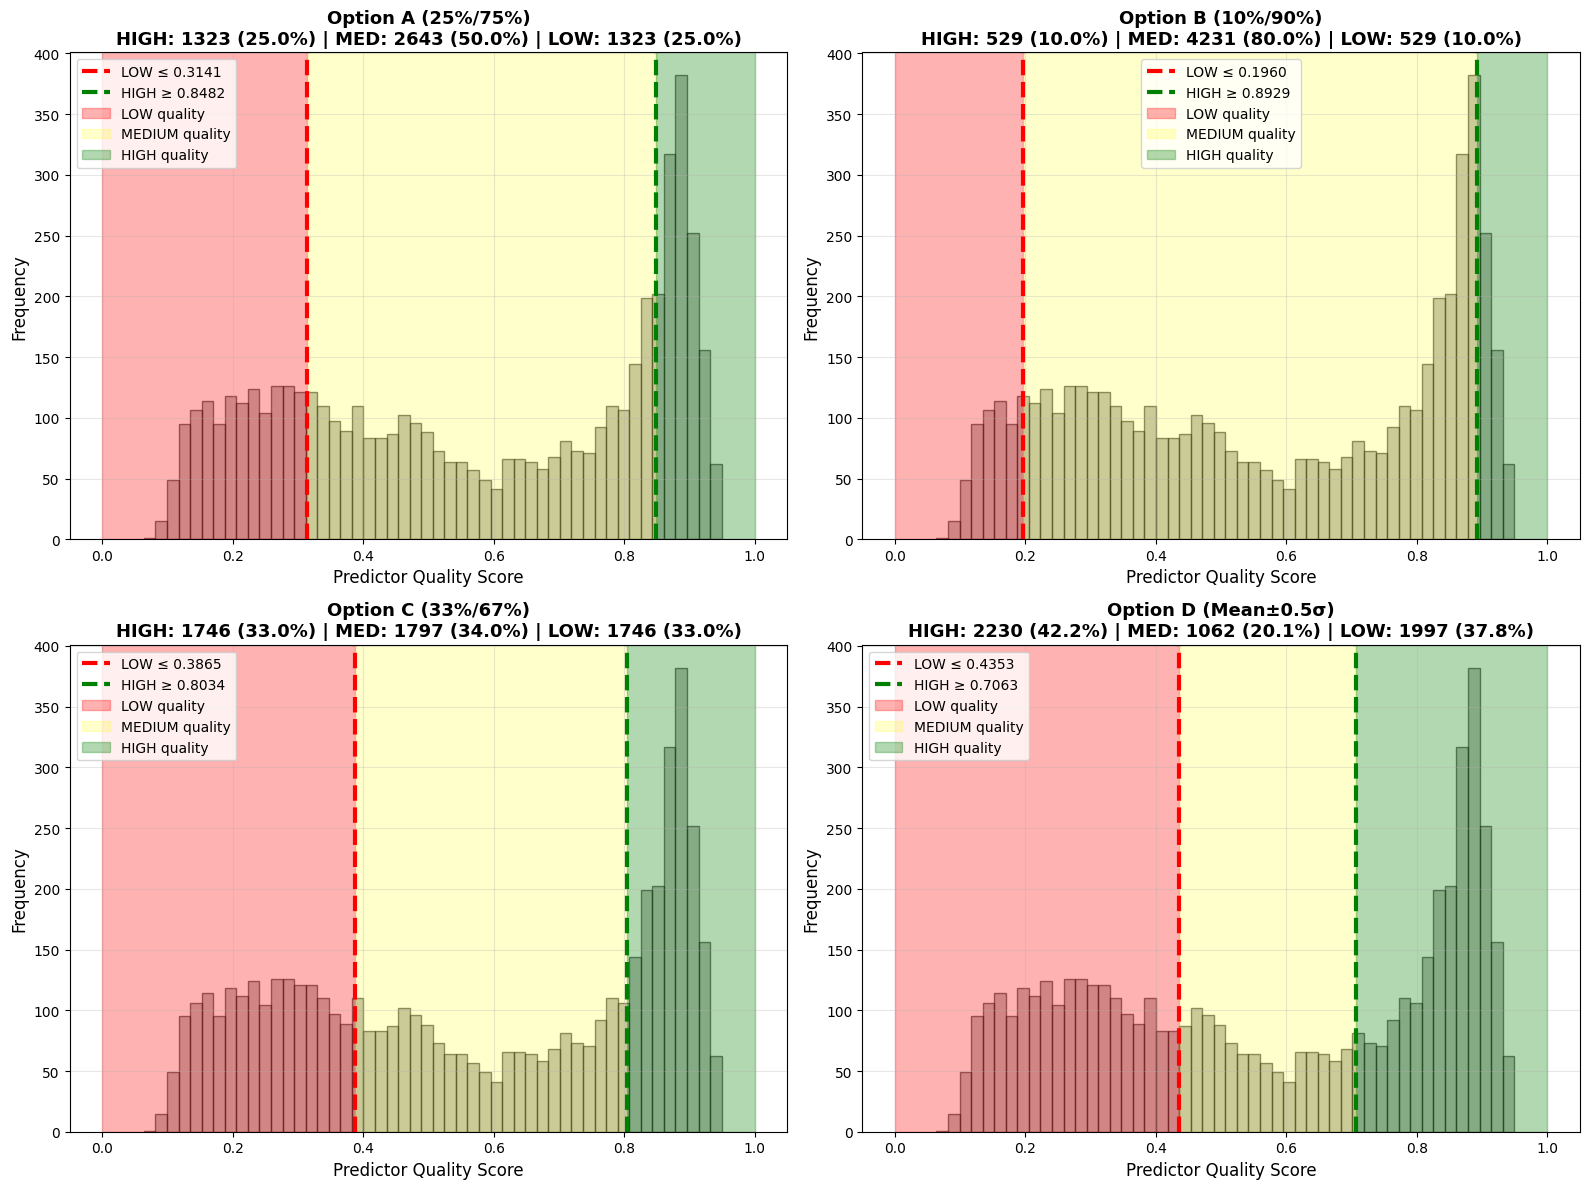

✓ Threshold comparison visualization saved


In [34]:
# Visualize threshold options
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for idx, (name, (low_th, high_th)) in enumerate(options.items()):
    ax = axes[idx // 2, idx % 2]
    
    # Histogram
    ax.hist(train_predictor_scores, bins=50, edgecolor='black', alpha=0.5, color='gray')
    
    # Threshold lines
    ax.axvline(low_th, color='red', linestyle='--', linewidth=3, label=f'LOW ≤ {low_th:.4f}')
    ax.axvline(high_th, color='green', linestyle='--', linewidth=3, label=f'HIGH ≥ {high_th:.4f}')
    
    # Fill regions
    ax.axvspan(0, low_th, alpha=0.3, color='red', label='LOW quality')
    ax.axvspan(low_th, high_th, alpha=0.2, color='yellow', label='MEDIUM quality')
    ax.axvspan(high_th, 1, alpha=0.3, color='green', label='HIGH quality')
    
    # Counts
    high_count = (train_predictor_scores >= high_th).sum()
    low_count = (train_predictor_scores <= low_th).sum()
    medium_count = len(train_predictor_scores) - high_count - low_count
    
    ax.set_xlabel('Predictor Quality Score', fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.set_title(
        f'{name}\n'
        f'HIGH: {high_count} ({high_count/len(train_predictor_scores)*100:.1f}%) | '
        f'MED: {medium_count} ({medium_count/len(train_predictor_scores)*100:.1f}%) | '
        f'LOW: {low_count} ({low_count/len(train_predictor_scores)*100:.1f}%)',
        fontsize=13, fontweight='bold'
    )
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["output_dir"]) / "threshold_options_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("✓ Threshold comparison visualization saved")


Samples Near HIGH-MEDIUM Boundary (Mean + 0.5σ)

Boundary threshold: 0.7063

Selected samples (closest to boundary):
  1. CNUH_055             / 0022                     
     Predictor: 0.7065 (distance: 0.0003)
     LPIPS:     0.7615
  2. CNUH_151             / 0026                     
     Predictor: 0.7067 (distance: 0.0004)
     LPIPS:     0.7565
  3. CNUH_X_025           / 0027                     
     Predictor: 0.7069 (distance: 0.0007)
     LPIPS:     0.7792
  4. CNUH_X_164           / 0012                     
     Predictor: 0.7056 (distance: 0.0007)
     LPIPS:     0.7550
  5. CNUH_X_153           / 0009                     
     Predictor: 0.7071 (distance: 0.0008)
     LPIPS:     0.7048


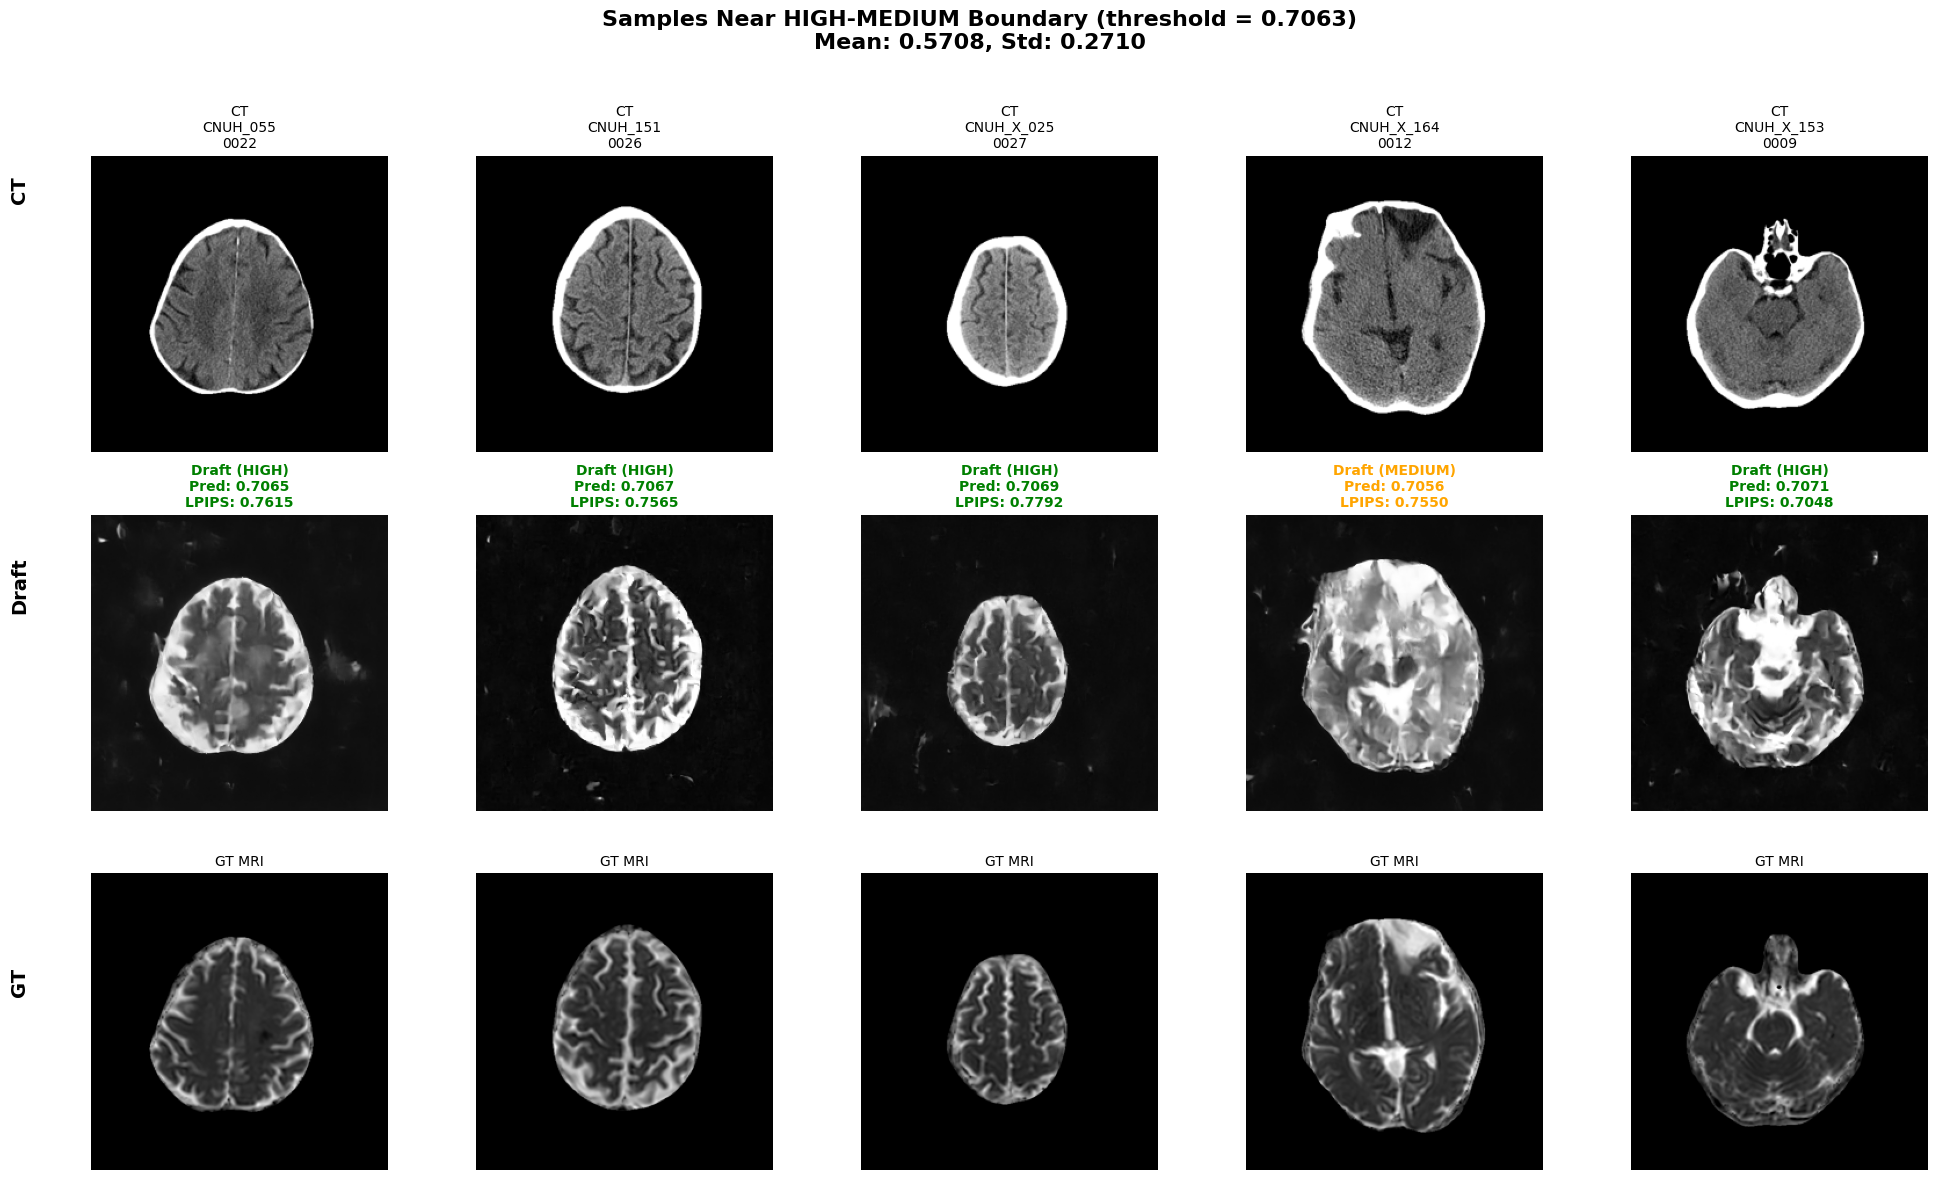


✓ Boundary samples visualization saved


In [35]:
# Visualize samples near HIGH-MEDIUM boundary (Mean + 0.5σ)
print("\n" + "="*80)
print("Samples Near HIGH-MEDIUM Boundary (Mean + 0.5σ)")
print("="*80)

boundary = mean_pred + 0.5 * std_pred
print(f"\nBoundary threshold: {boundary:.4f}")

# Find samples closest to the boundary
distances = np.abs(train_predictor_scores - boundary)
closest_indices = np.argsort(distances)[:5]

print("\nSelected samples (closest to boundary):")
for i, idx in enumerate(closest_indices, 1):
    sample = train_sample_info[idx]
    print(f"  {i}. {sample['patient']:20s} / {sample['slice_name']:25s}")
    print(f"     Predictor: {train_predictor_scores[idx]:.4f} (distance: {distances[idx]:.4f})")
    print(f"     LPIPS:     {train_lpips_scores[idx]:.4f}")

# Visualize
fig, axes = plt.subplots(3, 5, figsize=(20, 12))

for i, idx in enumerate(closest_indices):
    sample = train_sample_info[idx]
    
    # Find sample in dataset
    sample_idx = None
    for j, s in enumerate(train_dataset.samples):
        if s['patient'] == sample['patient'] and s['slice_name'] == sample['slice_name']:
            sample_idx = j
            break
    
    if sample_idx is None:
        continue
    
    # Load images
    ct = load_image(train_dataset.samples[sample_idx]['ct_path'])
    draft = load_image(train_dataset.samples[sample_idx]['draft_path'])
    gt = load_image(train_dataset.samples[sample_idx]['gt_path'])
    
    # CT
    axes[0, i].imshow(ct, cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f"CT\n{sample['patient'][:15]}\n{sample['slice_name'][:15]}", fontsize=10)
    axes[0, i].axis('off')
    
    # Draft
    axes[1, i].imshow(draft, cmap='gray', vmin=0, vmax=1)
    quality_label = "HIGH" if train_predictor_scores[idx] >= boundary else "MEDIUM"
    color = 'green' if quality_label == "HIGH" else 'orange'
    axes[1, i].set_title(
        f"Draft ({quality_label})\n"
        f"Pred: {train_predictor_scores[idx]:.4f}\n"
        f"LPIPS: {train_lpips_scores[idx]:.4f}",
        fontsize=10, color=color, fontweight='bold'
    )
    axes[1, i].axis('off')
    
    # GT
    axes[2, i].imshow(gt, cmap='gray', vmin=0, vmax=1)
    axes[2, i].set_title("GT MRI", fontsize=10)
    axes[2, i].axis('off')

# Row labels
fig.text(0.02, 0.83, 'CT', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
fig.text(0.02, 0.50, 'Draft', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
fig.text(0.02, 0.17, 'GT', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)

plt.suptitle(
    f'Samples Near HIGH-MEDIUM Boundary (threshold = {boundary:.4f})\n'
    f'Mean: {mean_pred:.4f}, Std: {std_pred:.4f}',
    fontsize=16, fontweight='bold', y=0.98
)
plt.tight_layout(rect=[0.03, 0, 1, 0.96])
plt.savefig(Path(CFG["output_dir"]) / "boundary_samples_high_medium.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Boundary samples visualization saved")
print("="*80)

In [39]:
# Apply different thresholds and show statistics
print("\n" + "="*80)
print("Threshold Application Statistics")
print("="*80)

options = {
    'Option A (25%/75%)': (low_threshold_pred, high_threshold_pred),
    'Option B (10%/90%)': (low_threshold_pred_10, high_threshold_pred_10),
    'Option C (33%/67%)': (low_threshold_pred_33, high_threshold_pred_33),
    'Option D (Mean±1σ)': (mean_pred - 1*std_pred, mean_pred + 1*std_pred),
}

for name, (low_th, high_th) in options.items():
    high_quality = train_predictor_scores >= high_th
    low_quality = train_predictor_scores <= low_th
    medium_quality = ~(high_quality | low_quality)
    
    print(f"\n{name}:")
    print(f"  Thresholds: LOW ≤ {low_th:.4f}, HIGH ≥ {high_th:.4f}")
    print(f"  HIGH quality:   {high_quality.sum():5d} samples ({high_quality.sum()/len(train_predictor_scores)*100:.1f}%)")
    print(f"  MEDIUM quality: {medium_quality.sum():5d} samples ({medium_quality.sum()/len(train_predictor_scores)*100:.1f}%)")
    print(f"  LOW quality:    {low_quality.sum():5d} samples ({low_quality.sum()/len(train_predictor_scores)*100:.1f}%)")

print("\n" + "="*80)
print("💡 Recommendation for Stage 2:")
print("="*80)
print("\nOption A (25%/75%) - Balanced approach")
print(f"  - Skip Stage 2 if quality ≥ {high_threshold_pred:.4f}")
print(f"  - Apply normal refinement if {low_threshold_pred:.4f} < quality < {high_threshold_pred:.4f}")
print(f"  - Apply aggressive refinement if quality ≤ {low_threshold_pred:.4f}")
print("="*80)


Threshold Application Statistics

Option A (25%/75%):
  Thresholds: LOW ≤ 0.3141, HIGH ≥ 0.8482
  HIGH quality:    1323 samples (25.0%)
  MEDIUM quality:  2643 samples (50.0%)
  LOW quality:     1323 samples (25.0%)

Option B (10%/90%):
  Thresholds: LOW ≤ 0.1960, HIGH ≥ 0.8929
  HIGH quality:     529 samples (10.0%)
  MEDIUM quality:  4231 samples (80.0%)
  LOW quality:      529 samples (10.0%)

Option C (33%/67%):
  Thresholds: LOW ≤ 0.3865, HIGH ≥ 0.8034
  HIGH quality:    1746 samples (33.0%)
  MEDIUM quality:  1797 samples (34.0%)
  LOW quality:     1746 samples (33.0%)

Option D (Mean±1σ):
  Thresholds: LOW ≤ 0.2998, HIGH ≥ 0.8418
  HIGH quality:    1395 samples (26.4%)
  MEDIUM quality:  2666 samples (50.4%)
  LOW quality:     1228 samples (23.2%)

💡 Recommendation for Stage 2:

Option A (25%/75%) - Balanced approach
  - Skip Stage 2 if quality ≥ 0.8482
  - Apply normal refinement if 0.3141 < quality < 0.8482
  - Apply aggressive refinement if quality ≤ 0.3141


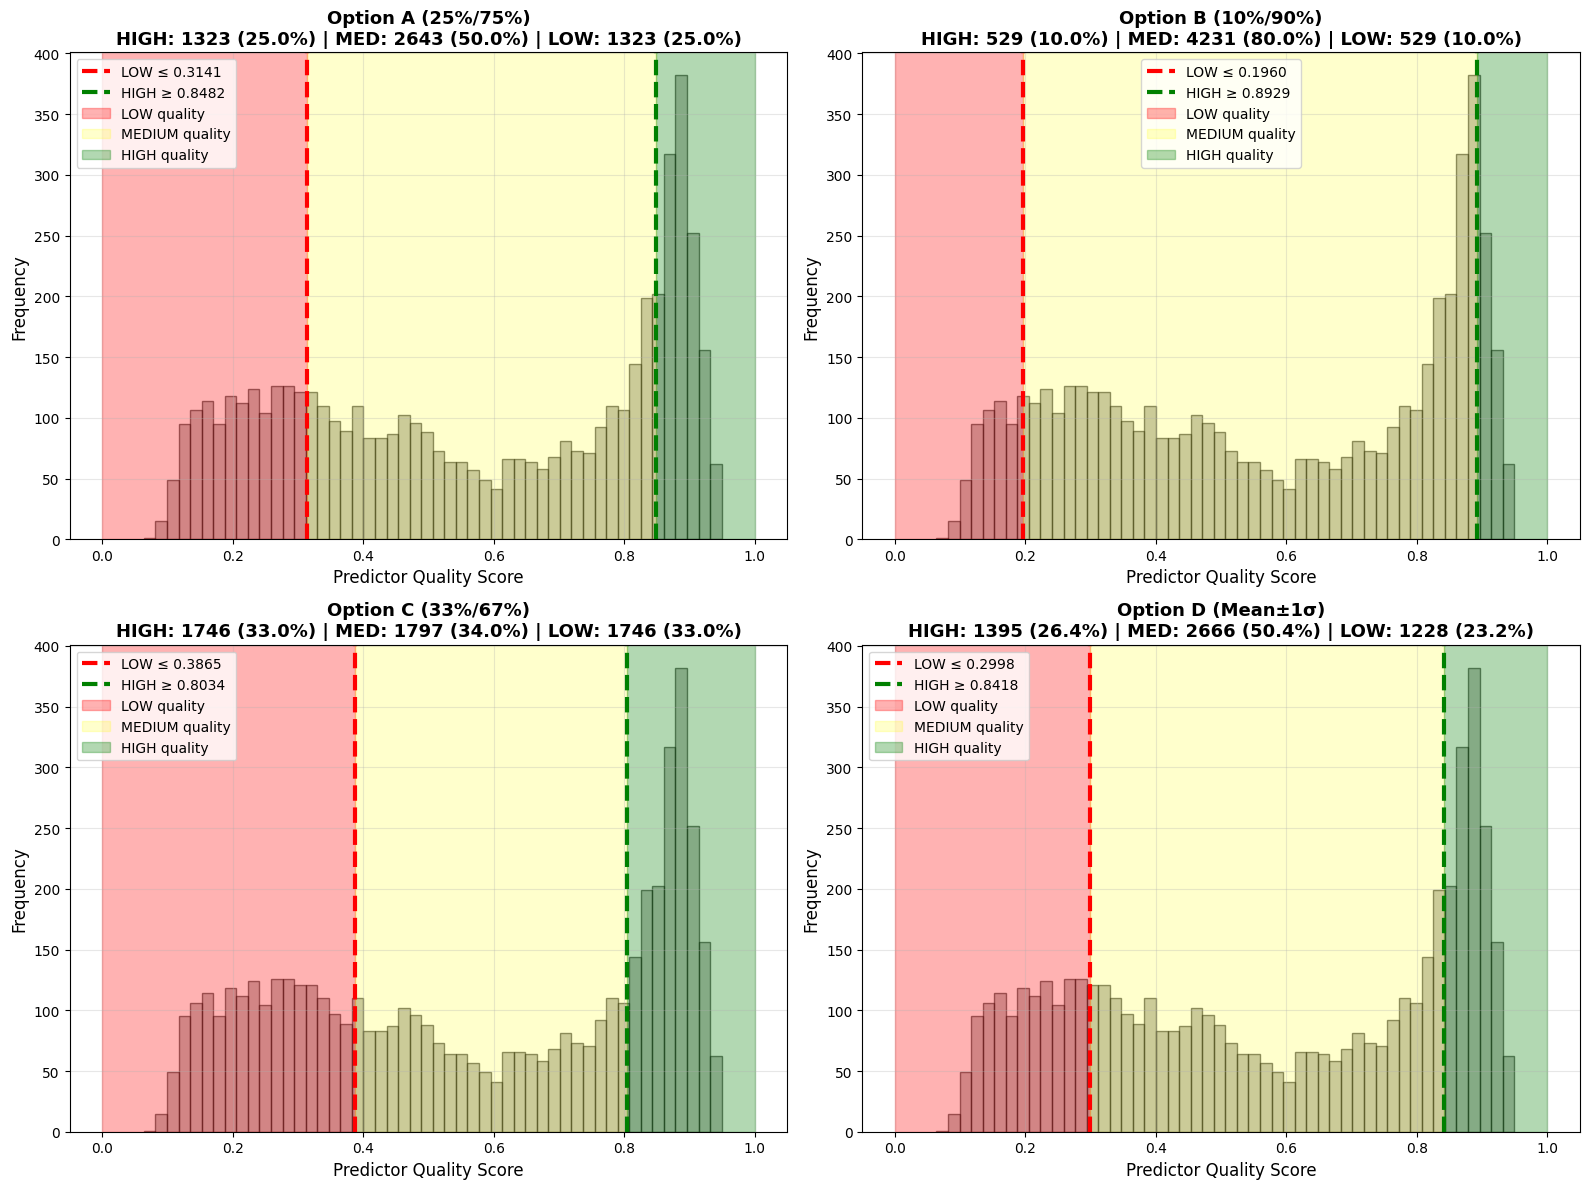

✓ Threshold comparison visualization saved


In [40]:
# Visualize threshold options
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for idx, (name, (low_th, high_th)) in enumerate(options.items()):
    ax = axes[idx // 2, idx % 2]
    
    # Histogram
    ax.hist(train_predictor_scores, bins=50, edgecolor='black', alpha=0.5, color='gray')
    
    # Threshold lines
    ax.axvline(low_th, color='red', linestyle='--', linewidth=3, label=f'LOW ≤ {low_th:.4f}')
    ax.axvline(high_th, color='green', linestyle='--', linewidth=3, label=f'HIGH ≥ {high_th:.4f}')
    
    # Fill regions
    ax.axvspan(0, low_th, alpha=0.3, color='red', label='LOW quality')
    ax.axvspan(low_th, high_th, alpha=0.2, color='yellow', label='MEDIUM quality')
    ax.axvspan(high_th, 1, alpha=0.3, color='green', label='HIGH quality')
    
    # Counts
    high_count = (train_predictor_scores >= high_th).sum()
    low_count = (train_predictor_scores <= low_th).sum()
    medium_count = len(train_predictor_scores) - high_count - low_count
    
    ax.set_xlabel('Predictor Quality Score', fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.set_title(
        f'{name}\n'
        f'HIGH: {high_count} ({high_count/len(train_predictor_scores)*100:.1f}%) | '
        f'MED: {medium_count} ({medium_count/len(train_predictor_scores)*100:.1f}%) | '
        f'LOW: {low_count} ({low_count/len(train_predictor_scores)*100:.1f}%)',
        fontsize=13, fontweight='bold'
    )
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["output_dir"]) / "threshold_options_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("✓ Threshold comparison visualization saved")


Samples Near HIGH-MEDIUM Boundary (Mean + 1σ)

Boundary threshold: 0.8418

Selected samples (closest to boundary):
  1. CNUH_107             / 0018                     
     Predictor: 0.8417 (distance: 0.0000)
     LPIPS:     0.8529
  2. CNUH_175             / 0023                     
     Predictor: 0.8417 (distance: 0.0000)
     LPIPS:     0.8462
  3. CNUH_148             / 0012                     
     Predictor: 0.8417 (distance: 0.0001)
     LPIPS:     0.8612
  4. CNUH_X_061           / 0015                     
     Predictor: 0.8418 (distance: 0.0001)
     LPIPS:     0.8472
  5. CNUH_X_157           / 0019                     
     Predictor: 0.8419 (distance: 0.0001)
     LPIPS:     0.8721


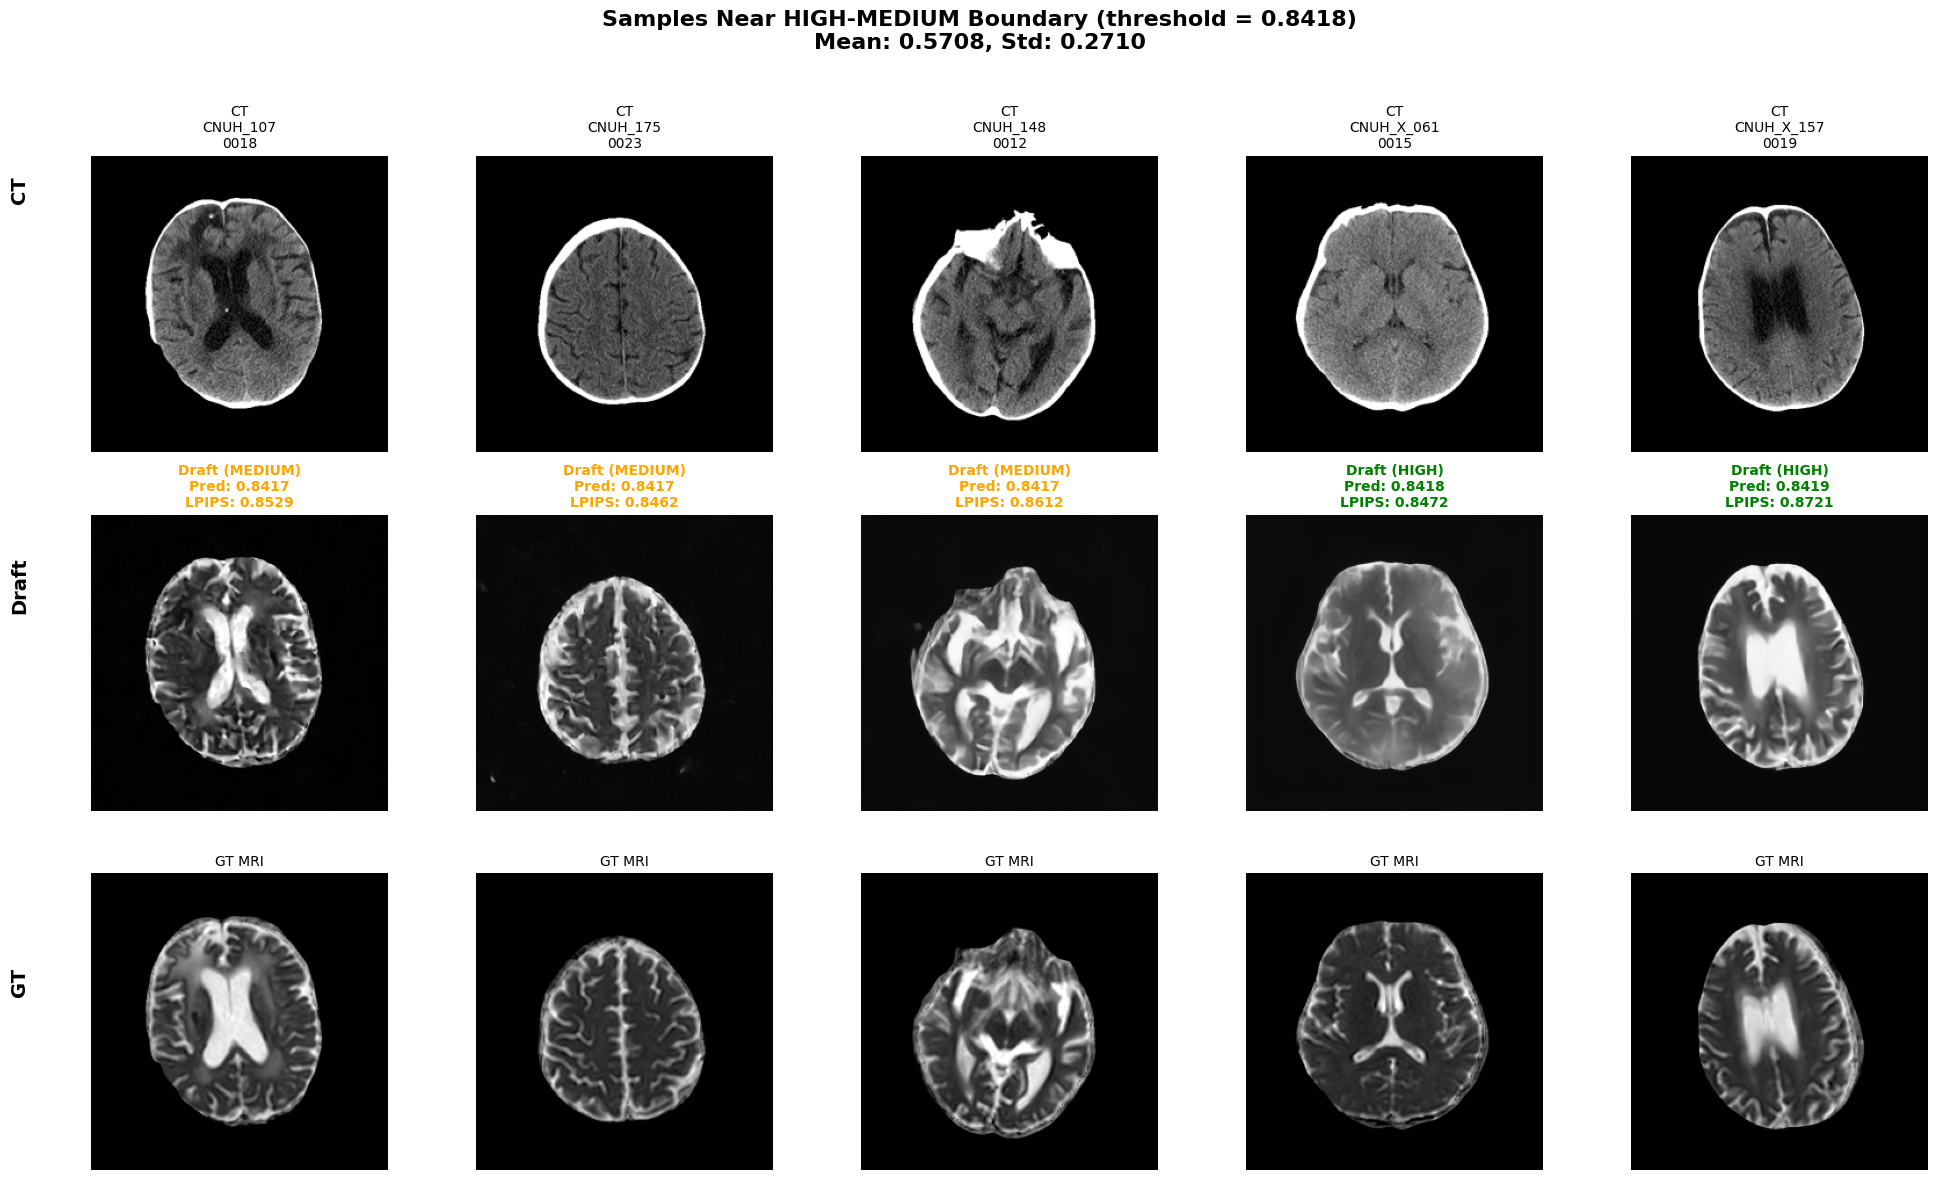


✓ Boundary samples visualization saved


In [41]:
# Visualize samples near HIGH-MEDIUM boundary (Mean + 0.5σ)
print("\n" + "="*80)
print("Samples Near HIGH-MEDIUM Boundary (Mean + 1σ)")
print("="*80)

boundary = mean_pred + 1 * std_pred
print(f"\nBoundary threshold: {boundary:.4f}")

# Find samples closest to the boundary
distances = np.abs(train_predictor_scores - boundary)
closest_indices = np.argsort(distances)[:5]

print("\nSelected samples (closest to boundary):")
for i, idx in enumerate(closest_indices, 1):
    sample = train_sample_info[idx]
    print(f"  {i}. {sample['patient']:20s} / {sample['slice_name']:25s}")
    print(f"     Predictor: {train_predictor_scores[idx]:.4f} (distance: {distances[idx]:.4f})")
    print(f"     LPIPS:     {train_lpips_scores[idx]:.4f}")

# Visualize
fig, axes = plt.subplots(3, 5, figsize=(20, 12))

for i, idx in enumerate(closest_indices):
    sample = train_sample_info[idx]
    
    # Find sample in dataset
    sample_idx = None
    for j, s in enumerate(train_dataset.samples):
        if s['patient'] == sample['patient'] and s['slice_name'] == sample['slice_name']:
            sample_idx = j
            break
    
    if sample_idx is None:
        continue
    
    # Load images
    ct = load_image(train_dataset.samples[sample_idx]['ct_path'])
    draft = load_image(train_dataset.samples[sample_idx]['draft_path'])
    gt = load_image(train_dataset.samples[sample_idx]['gt_path'])
    
    # CT
    axes[0, i].imshow(ct, cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f"CT\n{sample['patient'][:15]}\n{sample['slice_name'][:15]}", fontsize=10)
    axes[0, i].axis('off')
    
    # Draft
    axes[1, i].imshow(draft, cmap='gray', vmin=0, vmax=1)
    quality_label = "HIGH" if train_predictor_scores[idx] >= boundary else "MEDIUM"
    color = 'green' if quality_label == "HIGH" else 'orange'
    axes[1, i].set_title(
        f"Draft ({quality_label})\n"
        f"Pred: {train_predictor_scores[idx]:.4f}\n"
        f"LPIPS: {train_lpips_scores[idx]:.4f}",
        fontsize=10, color=color, fontweight='bold'
    )
    axes[1, i].axis('off')
    
    # GT
    axes[2, i].imshow(gt, cmap='gray', vmin=0, vmax=1)
    axes[2, i].set_title("GT MRI", fontsize=10)
    axes[2, i].axis('off')

# Row labels
fig.text(0.02, 0.83, 'CT', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
fig.text(0.02, 0.50, 'Draft', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
fig.text(0.02, 0.17, 'GT', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)

plt.suptitle(
    f'Samples Near HIGH-MEDIUM Boundary (threshold = {boundary:.4f})\n'
    f'Mean: {mean_pred:.4f}, Std: {std_pred:.4f}',
    fontsize=16, fontweight='bold', y=0.98
)
plt.tight_layout(rect=[0.03, 0, 1, 0.96])
plt.savefig(Path(CFG["output_dir"]) / "boundary_samples_high_medium.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Boundary samples visualization saved")
print("="*80)

## Feature Extractor 
- feature distribution을 배우는 방식으로 quality를 확인하려고 했는데, 문제가 생김

In [10]:
class FeatureExtractor(nn.Module):
    """
    Feature extractor for distribution matching
    Uses pre-trained model to extract high-level features
    """
    
    def __init__(self, backbone='resnet50'):
        super().__init__()
        
        if backbone == 'resnet50':
            resnet = models.resnet50(pretrained=True)
            self.features = nn.Sequential(*list(resnet.children())[:-1])
            self.feat_dim = 2048
        elif backbone == 'vgg16':
            vgg = models.vgg16(pretrained=True)
            self.features = nn.Sequential(*list(vgg.features.children())[:23])
            self.pool = nn.AdaptiveAvgPool2d(1)
            self.feat_dim = 512
        elif backbone == 'densenet121':
            densenet = models.densenet121(pretrained=True)
            self.features = densenet.features
            self.pool = nn.AdaptiveAvgPool2d(1)
            self.feat_dim = 1024
        else:
            raise ValueError(f"Unknown backbone: {backbone}")
        
        self.backbone = backbone
        self.eval()
        
        # Freeze all parameters
        for param in self.parameters():
            param.requires_grad = False
    
    def forward(self, x):
        # x: [B, 1, H, W]
        x = x.repeat(1, 3, 1, 1)  # → [B, 3, H, W]
        feat = self.features(x)
        
        if self.backbone in ['vgg16', 'densenet121']:
            feat = self.pool(feat)
        
        feat = feat.flatten(1)  # [B, feat_dim]
        return feat


In [11]:
@torch.no_grad()
def extract_all_features(dataset, feature_extractor, device, desc="Extracting features"):
    """
    Extract features for all images in dataset
    """
    feature_extractor.eval()
    
    loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=4)
    
    all_features = []
    all_sample_ids = []
    all_metas = []
    
    for batch in tqdm(loader, desc=desc):
        draft = batch['draft'].to(device)
        
        # Extract features
        features = feature_extractor(draft)
        
        all_features.append(features.cpu().numpy())
        all_sample_ids.extend(batch['sample_id'])
        all_metas.extend(batch['meta'])
    
    all_features = np.vstack(all_features)
    
    return all_features, all_sample_ids, all_metas

In [12]:
@torch.no_grad()
def extract_real_mri_features(data_root, feature_extractor, device):
    """
    Extract features from all real MRI images
    """
    print("\n" + "="*80)
    print("Extracting Real MRI Features (Option 2)")
    print("="*80)
    
    feature_extractor.eval()
    
    all_features = []
    all_ids = []
    
    for group in ['bleed', 'non_bleed']:
        group_dir = Path(data_root) / group
        if not group_dir.exists():
            continue
        
        for patient_dir in tqdm(sorted(group_dir.iterdir()), desc=f"Processing {group}"):
            if not patient_dir.is_dir():
                continue
            
            mri_dir = patient_dir / 'mri_b0_axial'
            if not mri_dir.exists():
                continue
            
            for mri_file in sorted(mri_dir.glob('*.png')):
                # Load MRI
                mri = load_image(mri_file, 256)
                mri_t = torch.from_numpy(mri).unsqueeze(0).unsqueeze(0).float()
                mri_t = mri_t * 2 - 1  # [-1, 1]
                mri_t = mri_t.to(device)
                
                # Extract features
                feat = feature_extractor(mri_t)
                
                all_features.append(feat.cpu().numpy())
                all_ids.append(f"{patient_dir.name}_{mri_file.stem}")
    
    all_features = np.vstack(all_features)
    
    print(f"\n✓ Extracted features from {len(all_features)} real MRI images")
    print(f"  Feature dimension: {all_features.shape[1]}")
    print("="*80)
    
    return all_features, all_ids

In [13]:
# Initialize feature extractor
feature_extractor = FeatureExtractor(backbone=CFG["feature_model"]).to(CFG["device"])

print(f"\n✓ FeatureExtractor initialized")
print(f"  Backbone: {CFG['feature_model']}")
print(f"  Feature dimension: {feature_extractor.feat_dim}")

# Extract features
real_mri_features, real_mri_ids = extract_real_mri_features(
    CFG["data_root"],
    feature_extractor,
    CFG["device"]
)

train_draft_features, train_draft_ids, train_draft_metas = extract_all_features(
    train_dataset,
    feature_extractor,
    CFG["device"],
    desc="Extracting train draft features"
)

val_draft_features, val_draft_ids, val_draft_metas = extract_all_features(
    val_dataset,
    feature_extractor,
    CFG["device"],
    desc="Extracting val draft features"
)


✓ FeatureExtractor initialized
  Backbone: resnet50
  Feature dimension: 2048

Extracting Real MRI Features (Option 2)


Processing non_bleed: 100%|██████████| 192/192 [00:18<00:00, 10.27it/s]



✓ Extracted features from 5878 real MRI images
  Feature dimension: 2048


Extracting val draft features: 100%|██████████| 19/19 [00:01<00:00, 19.00it/s]


In [14]:
def fit_gmm_distribution(features, n_components=10):
    """
    Fit Gaussian Mixture Model to real MRI features
    """
    print("\n" + "="*80)
    print(f"Fitting GMM with {n_components} components")
    print("="*80)
    
    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type='full',
        random_state=CFG["seed"],
        verbose=1,
        max_iter=200
    )
    
    gmm.fit(features)
    
    print(f"\n✓ GMM fitted")
    print(f"  Converged: {gmm.converged_}")
    print(f"  Iterations: {gmm.n_iter_}")
    print(f"  BIC: {gmm.bic(features):.2f}")
    print(f"  AIC: {gmm.aic(features):.2f}")
    print("="*80)
    
    return gmm

In [15]:
# Fit GMM on real MRI features
gmm = fit_gmm_distribution(real_mri_features, n_components=CFG["n_gmm_components"])

# Save GMM
with open(Path(CFG["output_dir"]) / "gmm_model.pkl", 'wb') as f:
    pickle.dump(gmm, f)

print("✓ GMM model saved")


Fitting GMM with 10 components
Initialization 0
Initialization converged.

✓ GMM fitted
  Converged: True
  Iterations: 2
  BIC: 71396994.60
  AIC: -68876435.20
✓ GMM model saved


In [16]:
def compute_distribution_quality(features, gmm):
    """
    Compute quality score based on GMM log-likelihood
    Higher = more similar to real MRI distribution
    """
    log_probs = gmm.score_samples(features)
    
    # Convert to 0-1 range using sigmoid
    # Adjust the scaling factor based on typical log_prob range
    quality_scores = 1 / (1 + np.exp(-log_probs / 50))
    
    return quality_scores

In [17]:
print("\n" + "="*80)
print("Computing Quality Scores")
print("="*80)

# Real MRI quality (should be high)
real_quality = compute_distribution_quality(real_mri_features, gmm)

# Draft quality
train_draft_quality = compute_distribution_quality(train_draft_features, gmm)
val_draft_quality = compute_distribution_quality(val_draft_features, gmm)

print(f"\n✓ Quality scores computed")
print(f"\nReal MRI quality:")
print(f"  Mean: {real_quality.mean():.4f}")
print(f"  Std:  {real_quality.std():.4f}")
print(f"  Min:  {real_quality.min():.4f}")
print(f"  Max:  {real_quality.max():.4f}")

print(f"\nTrain Draft quality:")
print(f"  Mean: {train_draft_quality.mean():.4f}")
print(f"  Std:  {train_draft_quality.std():.4f}")
print(f"  Min:  {train_draft_quality.min():.4f}")
print(f"  Max:  {train_draft_quality.max():.4f}")

print(f"\nVal Draft quality:")
print(f"  Mean: {val_draft_quality.mean():.4f}")
print(f"  Std:  {val_draft_quality.std():.4f}")
print(f"  Min:  {val_draft_quality.min():.4f}")
print(f"  Max:  {val_draft_quality.max():.4f}")

print("="*80)


Computing Quality Scores

✓ Quality scores computed

Real MRI quality:
  Mean: 1.0000
  Std:  0.0000
  Min:  1.0000
  Max:  1.0000

Train Draft quality:
  Mean: 0.0000
  Std:  0.0000
  Min:  0.0000
  Max:  0.0000

Val Draft quality:
  Mean: 0.0000
  Std:  0.0000
  Min:  0.0000
  Max:  0.0000


In [18]:
# Load best predictor
checkpoint = torch.load(Path(CFG["output_dir"]) / "best_quality_predictor.pt")
predictor.load_state_dict(checkpoint['model_state_dict'])
predictor.eval()

print(f"✓ Loaded best predictor (epoch {checkpoint['epoch']}, corr={checkpoint['val_corr']:.4f})")

# Predict on validation set
predictor_val_scores = []

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Option 1: Predicting quality"):
        draft = batch['draft'].to(CFG["device"])
        quality = predictor(draft)
        predictor_val_scores.extend(quality.cpu().numpy().tolist())

predictor_val_scores = np.array(predictor_val_scores)

print(f"\n✓ Option 1 predictions complete")
print(f"  Mean: {predictor_val_scores.mean():.4f}")
print(f"  Std:  {predictor_val_scores.std():.4f}")
print(f"  Min:  {predictor_val_scores.min():.4f}")
print(f"  Max:  {predictor_val_scores.max():.4f}")

✓ Loaded best predictor (epoch 34, corr=0.9860)


Option 1: Predicting quality: 100%|██████████| 37/37 [00:00<00:00, 39.26it/s]


✓ Option 1 predictions complete
  Mean: 0.5697
  Std:  0.2724
  Min:  0.0866
  Max:  0.9446


In [19]:
# Compute LPIPS for validation set
lpips_val_scores = []

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Computing LPIPS ground truth"):
        draft = batch['draft'].to(CFG["device"])
        gt = batch['gt'].to(CFG["device"])
        
        draft_3ch = draft.repeat(1, 3, 1, 1)
        gt_3ch = gt.repeat(1, 3, 1, 1)
        
        lpips_score = lpips_model(draft_3ch, gt_3ch).squeeze()
        quality = 1 - lpips_score.clamp(0, 1)  # Convert to quality
        
        lpips_val_scores.extend(quality.cpu().numpy().tolist())

lpips_val_scores = np.array(lpips_val_scores)

print(f"\n✓ LPIPS ground truth computed")
print(f"  Mean: {lpips_val_scores.mean():.4f}")
print(f"  Std:  {lpips_val_scores.std():.4f}")
print(f"  Min:  {lpips_val_scores.min():.4f}")
print(f"  Max:  {lpips_val_scores.max():.4f}")

Computing LPIPS ground truth: 100%|██████████| 37/37 [00:00<00:00, 38.83it/s]


✓ LPIPS ground truth computed
  Mean: 0.5721
  Std:  0.2779
  Min:  0.0466
  Max:  0.9608


In [20]:
print("\n" + "="*80)
print("Correlation Analysis")
print("="*80)

# Option 1 vs LPIPS
pearson_opt1, _ = pearsonr(predictor_val_scores, lpips_val_scores)
spearman_opt1, _ = spearmanr(predictor_val_scores, lpips_val_scores)

# Option 2 vs LPIPS
pearson_opt2, _ = pearsonr(val_draft_quality, lpips_val_scores)
spearman_opt2, _ = spearmanr(val_draft_quality, lpips_val_scores)

print(f"\nOption 1 (Learned Predictor) vs LPIPS:")
print(f"  Pearson:  {pearson_opt1:.4f}")
print(f"  Spearman: {spearman_opt1:.4f}")

print(f"\nOption 2 (Distribution Matching) vs LPIPS:")
print(f"  Pearson:  {pearson_opt2:.4f}")
print(f"  Spearman: {spearman_opt2:.4f}")

print("\n" + "="*80)
print("Winner:")
if spearman_opt1 > spearman_opt2:
    print(f"  🏆 Option 1 (Learned Predictor) - Spearman: {spearman_opt1:.4f}")
else:
    print(f"  🏆 Option 2 (Distribution Matching) - Spearman: {spearman_opt2:.4f}")
print("="*80)



Correlation Analysis

Option 1 (Learned Predictor) vs LPIPS:
  Pearson:  0.9933
  Spearman: 0.9860

Option 2 (Distribution Matching) vs LPIPS:
  Pearson:  nan
  Spearman: nan

Winner:
  🏆 Option 2 (Distribution Matching) - Spearman: nan


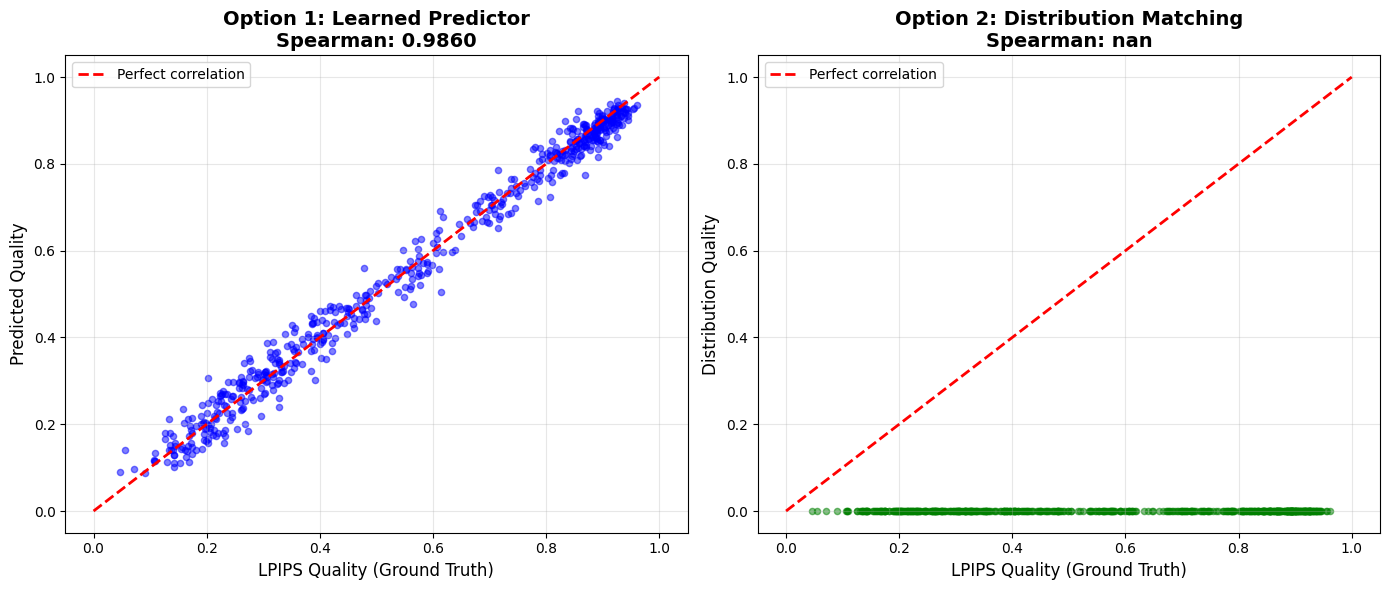

✓ Correlation plots saved


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Option 1
axes[0].scatter(lpips_val_scores, predictor_val_scores, alpha=0.5, s=20, c='blue')
axes[0].plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect correlation')
axes[0].set_xlabel('LPIPS Quality (Ground Truth)', fontsize=12)
axes[0].set_ylabel('Predicted Quality', fontsize=12)
axes[0].set_title(f'Option 1: Learned Predictor\nSpearman: {spearman_opt1:.4f}', 
                  fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Option 2
axes[1].scatter(lpips_val_scores, val_draft_quality, alpha=0.5, s=20, c='green')
axes[1].plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect correlation')
axes[1].set_xlabel('LPIPS Quality (Ground Truth)', fontsize=12)
axes[1].set_ylabel('Distribution Quality', fontsize=12)
axes[1].set_title(f'Option 2: Distribution Matching\nSpearman: {spearman_opt2:.4f}',
                  fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["output_dir"]) / "correlation_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("✓ Correlation plots saved")



t-SNE Visualization
Sampling for t-SNE visualization...
  Target samples per group: 589
  Real MRI sampled: 589
  Draft sampled:    589

Running t-SNE on 1178 samples...
  This may take a few minutes...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1178 samples in 0.001s...
[t-SNE] Computed neighbors for 1178 samples in 0.093s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1178
[t-SNE] Computed conditional probabilities for sample 1178 / 1178
[t-SNE] Mean sigma: 2.946452
[t-SNE] KL divergence after 250 iterations with early exaggeration: 61.846840
[t-SNE] KL divergence after 1000 iterations: 0.875688

✓ t-SNE complete


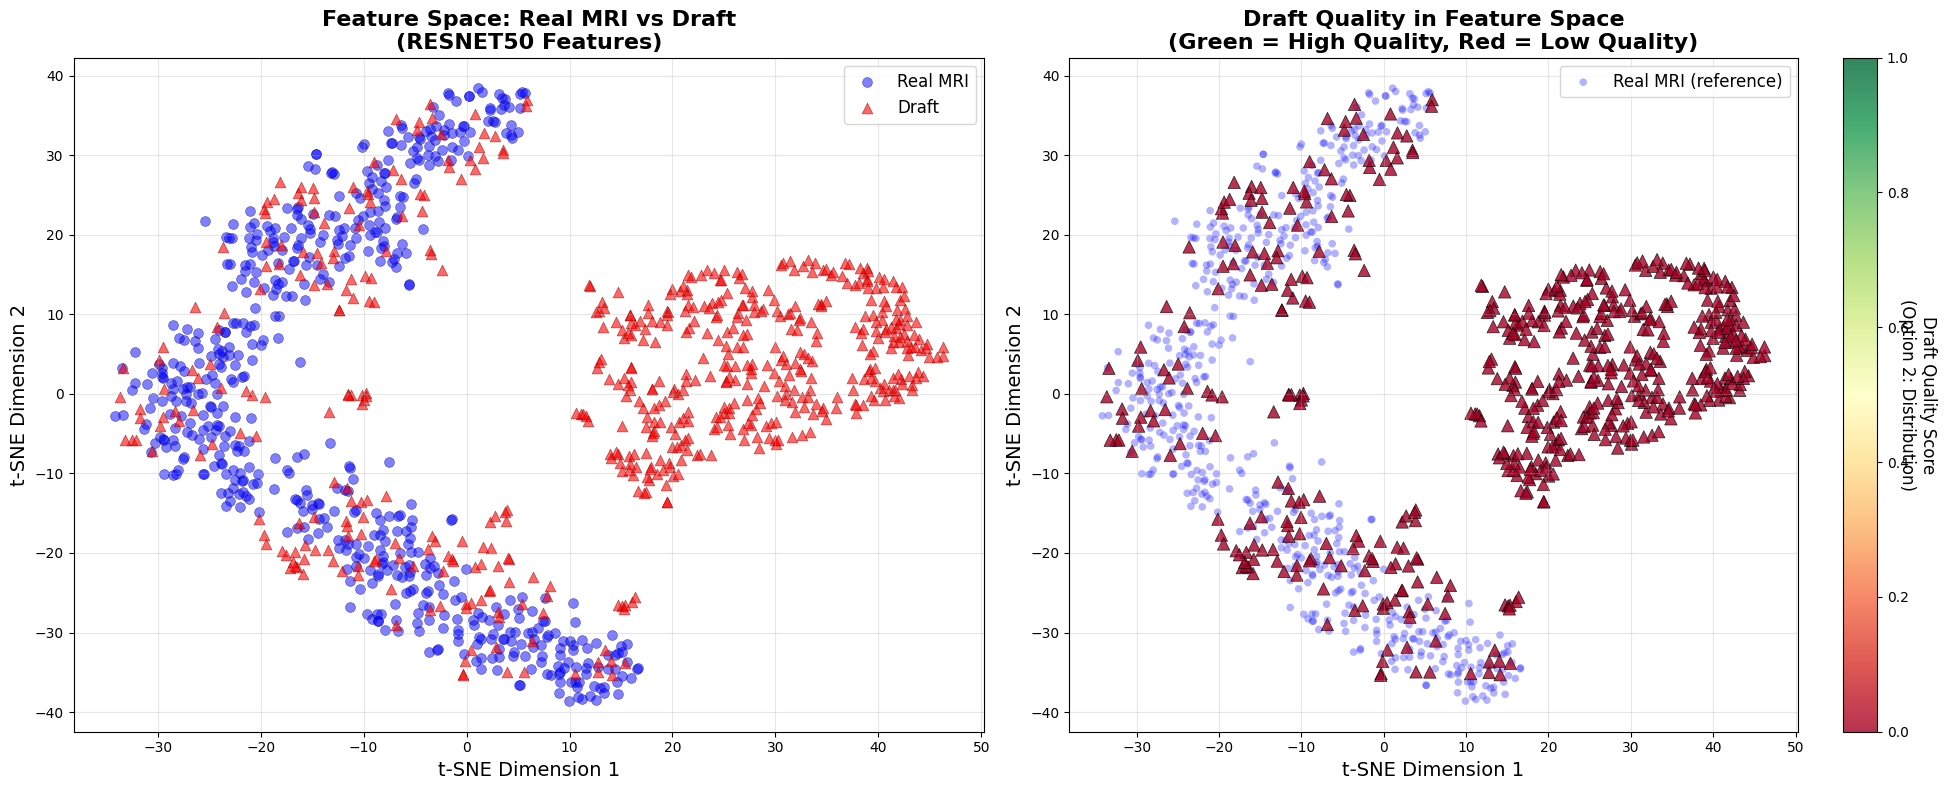

✓ t-SNE visualization saved


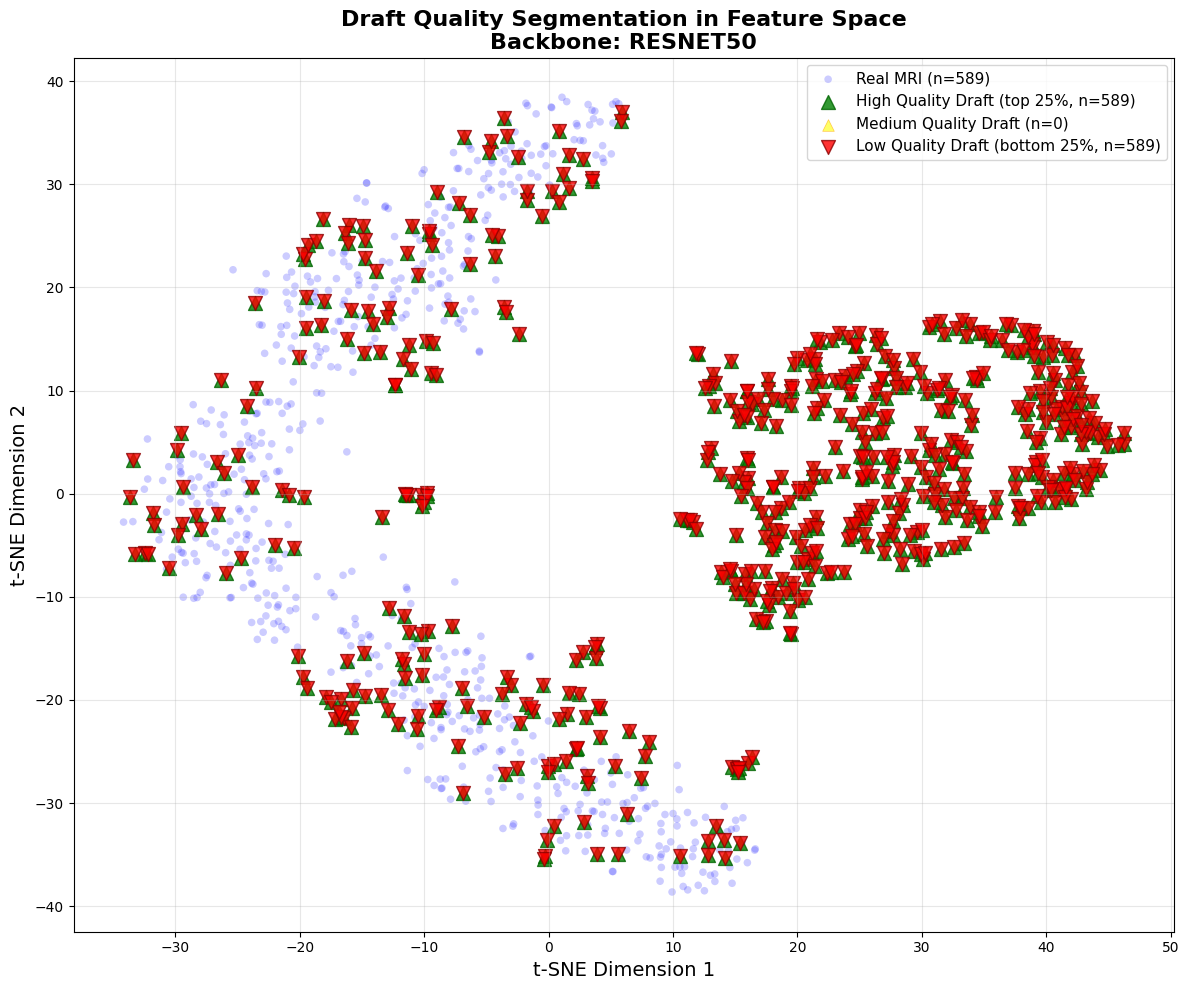

✓ Quality segmentation visualization saved

📊 Quality Statistics:
  High quality drafts:   589 (score ≥ 0.000)
  Medium quality drafts:   0
  Low quality drafts:    589 (score ≤ 0.000)


In [24]:
# ## 12. t-SNE Visualization of Feature Space

# In[22]:


print("\n" + "="*80)
print("t-SNE Visualization")
print("="*80)

# Sample for t-SNE (to reduce computation)
n_samples_per_group = min(CFG["tsne_samples"] // 2, len(real_mri_features), len(val_draft_features))

print(f"Sampling for t-SNE visualization...")
print(f"  Target samples per group: {n_samples_per_group}")

# Sample from each group
indices_real = np.random.choice(len(real_mri_features), n_samples_per_group, replace=False)
indices_draft = np.random.choice(len(val_draft_features), n_samples_per_group, replace=False)

sampled_real = real_mri_features[indices_real]
sampled_draft = val_draft_features[indices_draft]

print(f"  Real MRI sampled: {len(sampled_real)}")
print(f"  Draft sampled:    {len(sampled_draft)}")

# Combine
all_features_tsne = np.vstack([sampled_real, sampled_draft])
labels = np.array(['Real MRI'] * len(sampled_real) + ['Draft'] * len(sampled_draft))

# Get quality scores for color mapping
sampled_draft_quality = val_draft_quality[indices_draft]

print(f"\nRunning t-SNE on {len(all_features_tsne)} samples...")
print(f"  This may take a few minutes...")

# Run t-SNE with optimized parameters
tsne = TSNE(
    n_components=2, 
    random_state=CFG["seed"], 
    perplexity=30,
    n_iter=1000,
    verbose=1
)
features_2d = tsne.fit_transform(all_features_tsne)

print("\n✓ t-SNE complete")
print("="*80)


# In[23]:


# Plot 1: Simple Real vs Draft
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

real_mask = labels == 'Real MRI'
draft_mask = labels == 'Draft'

# Left plot: Simple distinction
axes[0].scatter(
    features_2d[real_mask, 0], 
    features_2d[real_mask, 1],
    c='blue', 
    alpha=0.5, 
    s=50, 
    label='Real MRI',
    edgecolors='darkblue',
    linewidth=0.5
)

axes[0].scatter(
    features_2d[draft_mask, 0], 
    features_2d[draft_mask, 1],
    c='red', 
    alpha=0.6, 
    s=60, 
    label='Draft', 
    marker='^',
    edgecolors='darkred',
    linewidth=0.5
)

axes[0].set_xlabel('t-SNE Dimension 1', fontsize=14)
axes[0].set_ylabel('t-SNE Dimension 2', fontsize=14)
axes[0].set_title(
    f'Feature Space: Real MRI vs Draft\n({CFG["feature_model"].upper()} Features)',
    fontsize=16, 
    fontweight='bold'
)
axes[0].legend(fontsize=12, loc='best')
axes[0].grid(alpha=0.3)

# Right plot: Draft colored by quality
scatter = axes[1].scatter(
    features_2d[real_mask, 0], 
    features_2d[real_mask, 1],
    c='blue', 
    alpha=0.3, 
    s=30,
    label='Real MRI (reference)',
    edgecolors='none'
)

scatter_draft = axes[1].scatter(
    features_2d[draft_mask, 0], 
    features_2d[draft_mask, 1],
    c=sampled_draft_quality,
    cmap='RdYlGn',  # Red (low) → Yellow → Green (high)
    alpha=0.8,
    s=80,
    marker='^',
    edgecolors='black',
    linewidth=0.5,
    vmin=0,
    vmax=1
)

cbar = plt.colorbar(scatter_draft, ax=axes[1])
cbar.set_label('Draft Quality Score\n(Option 2: Distribution)', fontsize=12, rotation=270, labelpad=20)

axes[1].set_xlabel('t-SNE Dimension 1', fontsize=14)
axes[1].set_ylabel('t-SNE Dimension 2', fontsize=14)
axes[1].set_title(
    'Draft Quality in Feature Space\n(Green = High Quality, Red = Low Quality)',
    fontsize=16,
    fontweight='bold'
)
axes[1].legend(fontsize=12, loc='best')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["output_dir"]) / "tsne_feature_space.png", dpi=150, bbox_inches='tight')
plt.show()

print("✓ t-SNE visualization saved")


# In[24]:


# Additional plot: High quality vs Low quality drafts
fig, ax = plt.subplots(figsize=(12, 10))

# Define quality thresholds
quality_threshold_high = np.percentile(sampled_draft_quality, 75)
quality_threshold_low = np.percentile(sampled_draft_quality, 25)

high_quality_mask = sampled_draft_quality >= quality_threshold_high
low_quality_mask = sampled_draft_quality <= quality_threshold_low
medium_quality_mask = ~(high_quality_mask | low_quality_mask)

draft_features_2d = features_2d[draft_mask]

# Plot Real MRI (background)
ax.scatter(
    features_2d[real_mask, 0],
    features_2d[real_mask, 1],
    c='blue',
    alpha=0.2,
    s=30,
    label=f'Real MRI (n={len(sampled_real)})',
    edgecolors='none'
)

# Plot drafts by quality
ax.scatter(
    draft_features_2d[high_quality_mask, 0],
    draft_features_2d[high_quality_mask, 1],
    c='green',
    alpha=0.8,
    s=100,
    marker='^',
    label=f'High Quality Draft (top 25%, n={high_quality_mask.sum()})',
    edgecolors='darkgreen',
    linewidth=1
)

ax.scatter(
    draft_features_2d[medium_quality_mask, 0],
    draft_features_2d[medium_quality_mask, 1],
    c='yellow',
    alpha=0.6,
    s=70,
    marker='^',
    label=f'Medium Quality Draft (n={medium_quality_mask.sum()})',
    edgecolors='orange',
    linewidth=0.5
)

ax.scatter(
    draft_features_2d[low_quality_mask, 0],
    draft_features_2d[low_quality_mask, 1],
    c='red',
    alpha=0.8,
    s=100,
    marker='v',
    label=f'Low Quality Draft (bottom 25%, n={low_quality_mask.sum()})',
    edgecolors='darkred',
    linewidth=1
)

ax.set_xlabel('t-SNE Dimension 1', fontsize=14)
ax.set_ylabel('t-SNE Dimension 2', fontsize=14)
ax.set_title(
    'Draft Quality Segmentation in Feature Space\n'
    f'Backbone: {CFG["feature_model"].upper()}',
    fontsize=16,
    fontweight='bold'
)
ax.legend(fontsize=11, loc='best')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["output_dir"]) / "tsne_quality_segmentation.png", dpi=150, bbox_inches='tight')
plt.show()

print("✓ Quality segmentation visualization saved")

# Statistics
print(f"\n📊 Quality Statistics:")
print(f"  High quality drafts:   {high_quality_mask.sum():3d} (score ≥ {quality_threshold_high:.3f})")
print(f"  Medium quality drafts: {medium_quality_mask.sum():3d}")
print(f"  Low quality drafts:    {low_quality_mask.sum():3d} (score ≤ {quality_threshold_low:.3f})")